### IMPORTING LIBRARY

In [1]:
import os
import random
import datetime
import json
import h5py
import umap
import pandas                   as pd
import numpy                    as np
import plotly.express           as px
import plotly.graph_objects     as go

import matplotlib.pyplot        as plt

from tqdm                       import tqdm
from preProcessingData          import PreProcessData
from utility.matpilotDraw       import MatPlot
from utility.plotloyDraw        import PlotlyDraw
from prettytable                import PrettyTable
from model.vaeConv1DCustom      import vaeConv1DCustom 
from vaeTrainer                 import appVAE
from mpl_toolkits.mplot3d       import Axes3D
from sklearn.cluster            import KMeans
from sklearn.cluster            import DBSCAN
from sklearn.preprocessing      import StandardScaler, MinMaxScaler
from matplotlib.colors          import Normalize




matPlot    = MatPlot() 
plotly     = PlotlyDraw()
preData    = PreProcessData()

/home/ducan/anaconda3/envs/tensorflow2.10.0/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-07-24 01:23:40.110214: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-07-24 01:23:40.275910: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2024-07-24 01:23:40.275927: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your ma

### DATA LOADING

In [ ]:
# Use this one only aiming to show the data summary 
rawDataH5 = preData.loadCriticalData()
print(rawDataH5.info())

### DATA CLEANING

#### Manipulated and efficiency Variables

In [ ]:
preData.splitInputandEfficiencyVar()

##### Draw variables

In [ ]:
# ============================
# Manipulated variables
# ----------------------------
for idxFeature in preData.manipulatedCr1:
    drawedData = preData.crusher1[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

In [ ]:
# ============================
# Efficiency variables
# ----------------------------
for idxFeature in preData.efficiencyCr1:
    drawedData = preData.crusher1[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

#### Sumarry MOF

In [ ]:
preData.sumarryMOF()

#### Data summarization

In [ ]:
markedPoints = preData.sumarryDataFromFile()

#### Add efficiency variables

In [ ]:
addedVariables = preData.additionEfficiencyVar(rawDataH5)

print(addedVariables.info())
print(addedVariables.isna())

## RECONSTRUCTION ERROR FOR MANIPULATED AND EFFICIENCY VARIABLES

In [ ]:
# HANDLE THE DATA BEFORE PREDICTION
# ======================================
#  LOAD THE CONFIG FILE
# --------------------------------------
with open('model/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
vaeConfig                   = config["vae"]
rawData         = preData.loadCriticalData()                                            # Load the data from critical file
_,healthyPos    = preData.getHealthyState(rawData)                                      # Load the healthy state for display purpose only
clearnData      = preData.cleanData(rawData[preData.crusher1Value])                     # Clean the data by using moving average
norData         = preData.normalizeBuilinFunction(clearnData[preData.crusher1Value])    # Normalize the data


### Manipulated variables

In [ ]:
vaeConfig["inFeatureDim"]   = 14
vaeConfig["outFeatureDim"]  = 14

# ======================================
#  PREPROCESS THE DATA
# --------------------------------------
inputX          = norData[preData.beauManipulatedCr1]                                   # Get the clean manipulated name
seqData         = preData.splitAndPadSequences([inputX,inputX],seqLength=vaeConfig['seqLength'], overlap= vaeConfig['overlap']) # Split data into each sequence

print(f"The size of the data: {seqData[0].shape} and {seqData[1].shape}")

# ======================================
#               MODEL 
# --------------------------------------
model       = vaeConv1DCustom(vaeConfig)
model.summary()


# ======================================
# PREDICT TO GET THE LATENT SPACE AND LOSS
# AND SAVE THE RESULT TO .H5 FILE
# --------------------------------------
lossResults,latentResults   = appVAE.predict(seqData,vaeConfig,ckptmanipulatedVarType=True)     

npLossResults               = np.array(lossResults)
npLatentResults             = np.array(latentResults)
with h5py.File('ckpt/otherResults/VAECNN1D_manipulatedCr1[200, 100, 50]_[50, 100, 200]latent_2_lossAndLatent.h5', 'w') as file:
    # Create datasets in the file
    file.create_dataset('lossResults',      data = npLossResults)
    file.create_dataset('latentResults',    data = npLatentResults)

print(len(lossResults))

In [ ]:
# ======================================
# VISUALIZE THE RESULT
# --------------------------------------
drawedData = preData.crusher1["corriente(A)"].to_numpy().astype(float)
time       = preData.crusher1["tiempo"]


with h5py.File('ckpt/otherResults/VAECNN1D_manipulatedCr1[200, 100, 50]_[50, 100, 200]latent_2_lossAndLatent.h5', 'r') as file:
    npLossResults   = file['lossResults'][:]
    npLatentResults = file['latentResults'][:]

padSize             = len(drawedData) - len(npLossResults)

npLossResultsPad    = np.pad(npLossResults, (padSize, 0), mode='constant', constant_values=0)
npLatentResultsPad  = np.pad(npLatentResults, (padSize, 0), mode='constant', constant_values=0)


plotly.plot_matrix(xData                = time,
                   yData                = [drawedData,npLossResultsPad,npLatentResultsPad],
                   title                = ["corriente(A)","Loss","Latent space"],
                   highLighHtPos        = healthyPos,
                   makeImportantEvent   = markedPoints,
                   withShap             = True
                   ) 

# addedVariables["constructionLoss"] = npLossResultsPad

### Efficiency variable

In [ ]:
vaeConfig["inFeatureDim"]   = 9
vaeConfig["outFeatureDim"]  = 9


inputX      = norData[preData.beauEfficiencyCr1]                                                                            # Get the clean manipulated name
seqData     = preData.splitAndPadSequences([inputX,inputX],seqLength=vaeConfig['seqLength'], overlap= vaeConfig['overlap']) # Split data into each sequence
print(f"The size of the data: {seqData[0].shape} and {seqData[1].shape}")


model       = vaeConv1DCustom(vaeConfig)
model.summary()


# ======================================
# PREDICT TO GET THE LATENT SPACE AND LOSS
# AND SAVE THE RESULT TO .H5 FILE
# --------------------------------------
lossResults,latentResults   = appVAE.predict(seqData,vaeConfig,ckptmanipulatedVarType=False)     

# lossResults     = [5.5,6.6,7.7]
# latentResults   = [5.5,6.6,7.7]
npLossResults               = np.array(lossResults)
npLatentResults             = np.array(latentResults)


with h5py.File('ckpt/otherResults/VAECNN1D_efficiencyCr1[200, 100, 50]_[50, 100, 200]latent_2_lossAndLatent.h5', 'w') as file:
    # Create datasets in the file
    file.create_dataset('lossResults',      data = npLossResults)
    file.create_dataset('latentResults',    data = npLatentResults)

print(len(lossResults))

In [ ]:
# ======================================
# VISUALIZE THE RESULT
# --------------------------------------
drawedData = preData.crusher1["corriente(A)"].to_numpy().astype(float)
time       = preData.crusher1["tiempo"]


with h5py.File('ckpt/otherResults/VAECNN1D_efficiencyCr1[200, 100, 50]_[50, 100, 200]latent_2_lossAndLatent.h5', 'r') as file:
    npLossResults   = file['lossResults'][:]
    npLatentResults = file['latentResults'][:]

padSize             = len(drawedData) - len(npLossResults)

npLossResultsPad    = np.pad(npLossResults, (padSize, 0), mode='constant', constant_values=0)
npLatentResultsPad  = np.pad(npLatentResults, (padSize, 0), mode='constant', constant_values=0)


plotly.plot_matrix(xData                = time,
                   yData                = [drawedData,npLossResultsPad,npLatentResultsPad],
                   title                = ["corriente(A)","Loss","Latent space"],
                   highLighHtPos        = healthyPos,
                   makeImportantEvent   = markedPoints,
                   withShap             = True
                   ) 

In [ ]:
# ============================
# Manipulated variables
# ----------------------------
for idxFeature in preData.manipulatedCr1:
    drawedData = norData[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

In [ ]:
# ============================
# Efficiency variables
# ----------------------------
for idxFeature in preData.efficiencyCr1:
    drawedData = norData[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

### GET RECONSTRUCTION ERROR AND LATENT SPACE

#### Check results

In [ ]:
matPlot.draw2D( xCoor                = time[158700:164472],
                yCoor                = npLossResultsPad[158700:164472],
                title                = ["Loss"],      
                ) 
matPlot.draw2D( xCoor                = time[198160:198519],
                yCoor                = npLossResultsPad[198160:198519],
                title                = ["Loss"],      
                ) 

matPlot.draw2D( xCoor                = time[284798:293894],
                yCoor                = npLossResultsPad[284798:293894],
                title                = ["Loss"],      
                ) 

matPlot.draw2D( xCoor                = time[168858,169727],
                yCoor                = npLossResultsPad[168858,169727],
                title                = ["Loss"],      
                ) 



## UMAP

### Using unsupervised UMAP with healthy data for new coordination

In [ ]:
rawData                     = preData.loadCriticalData()                    # Load the data from critical file
healthyData,healthyPos      = preData.getHealthyState(rawData)                                      # Load the healthy state for display purpose only


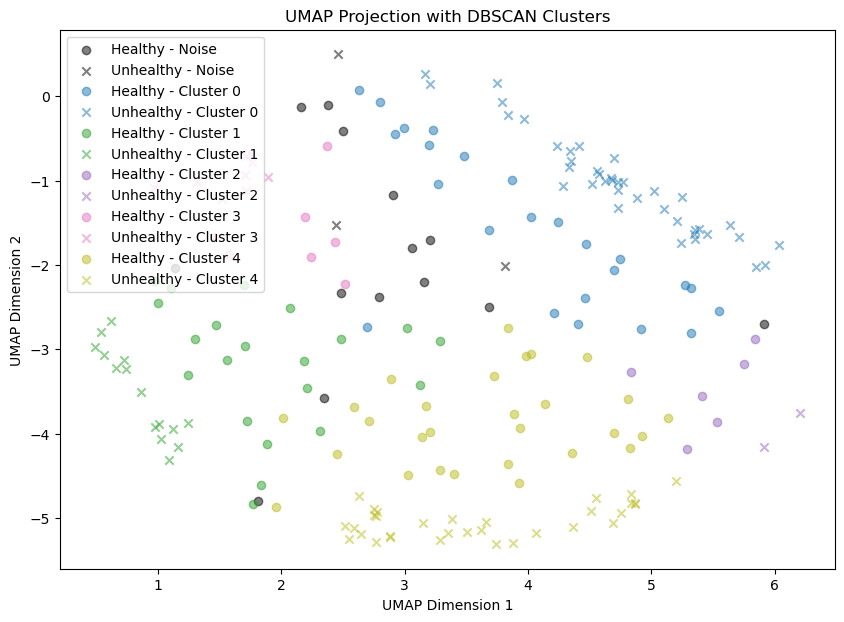

In [9]:
import numpy as np
import pandas as pd
import umap
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from matplotlib.colors import ListedColormap

# Example DataFrame
np.random.seed(42)
time = pd.date_range(start='1/1/2020', periods=200, freq='D')
data = np.random.rand(200, 10)
df = pd.DataFrame(data, columns=[f'Feature_{chr(65 + i)}' for i in range(10)])
df['time'] = time

# Assign some healthy and unhealthy data labels for demonstration
# Assuming the first 100 rows are healthy and the next 100 rows are unhealthy
df['status'] = ['healthy']*100 + ['unhealthy']*100

# Create dummy features for demonstration
healthy_data = df[df['status'] == 'healthy'].drop(['time', 'status'], axis=1)
unhealthy_data = df[df['status'] == 'unhealthy'].drop(['time', 'status'], axis=1)

# Standardize the features
scaler = StandardScaler()
scaled_healthy_data = scaler.fit_transform(healthy_data)
scaled_unhealthy_data = scaler.transform(unhealthy_data)

# Fit UMAP on the healthy data
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
healthy_embedding = reducer.fit_transform(scaled_healthy_data)

# Project all data (including unhealthy data) using the fitted UMAP
all_data = np.vstack([scaled_healthy_data, scaled_unhealthy_data])
all_embedding = reducer.transform(all_data)

# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(all_embedding)

# Split DBSCAN labels back into healthy and unhealthy data
dbscan_labels_healthy = dbscan_labels[:len(healthy_data)]
dbscan_labels_unhealthy = dbscan_labels[len(healthy_data):]

# Plot the UMAP projection with DBSCAN clusters
fig, ax = plt.subplots(figsize=(10, 7))

# Colors for clusters
unique_labels = np.unique(dbscan_labels)
colors = plt.cm.get_cmap('tab20', len(unique_labels))  # Use a colormap with enough colors

# Plot healthy data
for label in unique_labels:
    if label == -1:
        # Noise points
        color = 'k'
    else:
        color = colors(label)
    
    # Plot healthy data points
    ax.scatter(healthy_embedding[dbscan_labels_healthy == label, 0], 
               healthy_embedding[dbscan_labels_healthy == label, 1], 
               color=color, label=f'Healthy - Cluster {label}' if label != -1 else 'Healthy - Noise', 
               alpha=0.5)

    # Plot unhealthy data points
    ax.scatter(all_embedding[len(healthy_data) + np.where(dbscan_labels_unhealthy == label)[0], 0], 
               all_embedding[len(healthy_data) + np.where(dbscan_labels_unhealthy == label)[0], 1], 
               color=color, marker='x', label=f'Unhealthy - Cluster {label}' if label != -1 else 'Unhealthy - Noise', 
               alpha=0.5)

ax.set_title('UMAP Projection with DBSCAN Clusters')
ax.set_xlabel('UMAP Dimension 1')
ax.set_ylabel('UMAP Dimension 2')
ax.legend(loc='best')
plt.show()


### Using supervised UMAP

In [2]:
# =================================
# Preprocess the data and extract 
# the trajectory
# ---------------------------------
rawDataH5           = preData.loadCriticalData()                    # Load the data from critical file
addedVariablesData  = preData.additionEfficiencyVar(rawDataH5)      # Add some additional efficiency variable
normalizedData      = preData.normalizeBuilinFunction(addedVariablesData,  scaler = MinMaxScaler()) # Normalize the data
trajectory          = preData.getTrajectory(normalizedData)         # Extract the trajectory

dimReductionModels  =    umap.UMAP( n_components = 2,
                                    n_neighbors  = 15, 
                                    random_state = 40,
                                    min_dist     = 0.5
                                    )

Process:525013||2024-07-24 01:23:52,014-INFO [preProcessingData.py:loadCriticalData():218]:Loading critical MOF data from files ...
Process:525013||2024-07-24 01:23:54,082-INFO [preProcessingData.py:loadCriticalData():224]:Finish loading data from files ...


29


#### For efficiency variables

The MOF Válvula defectuosa


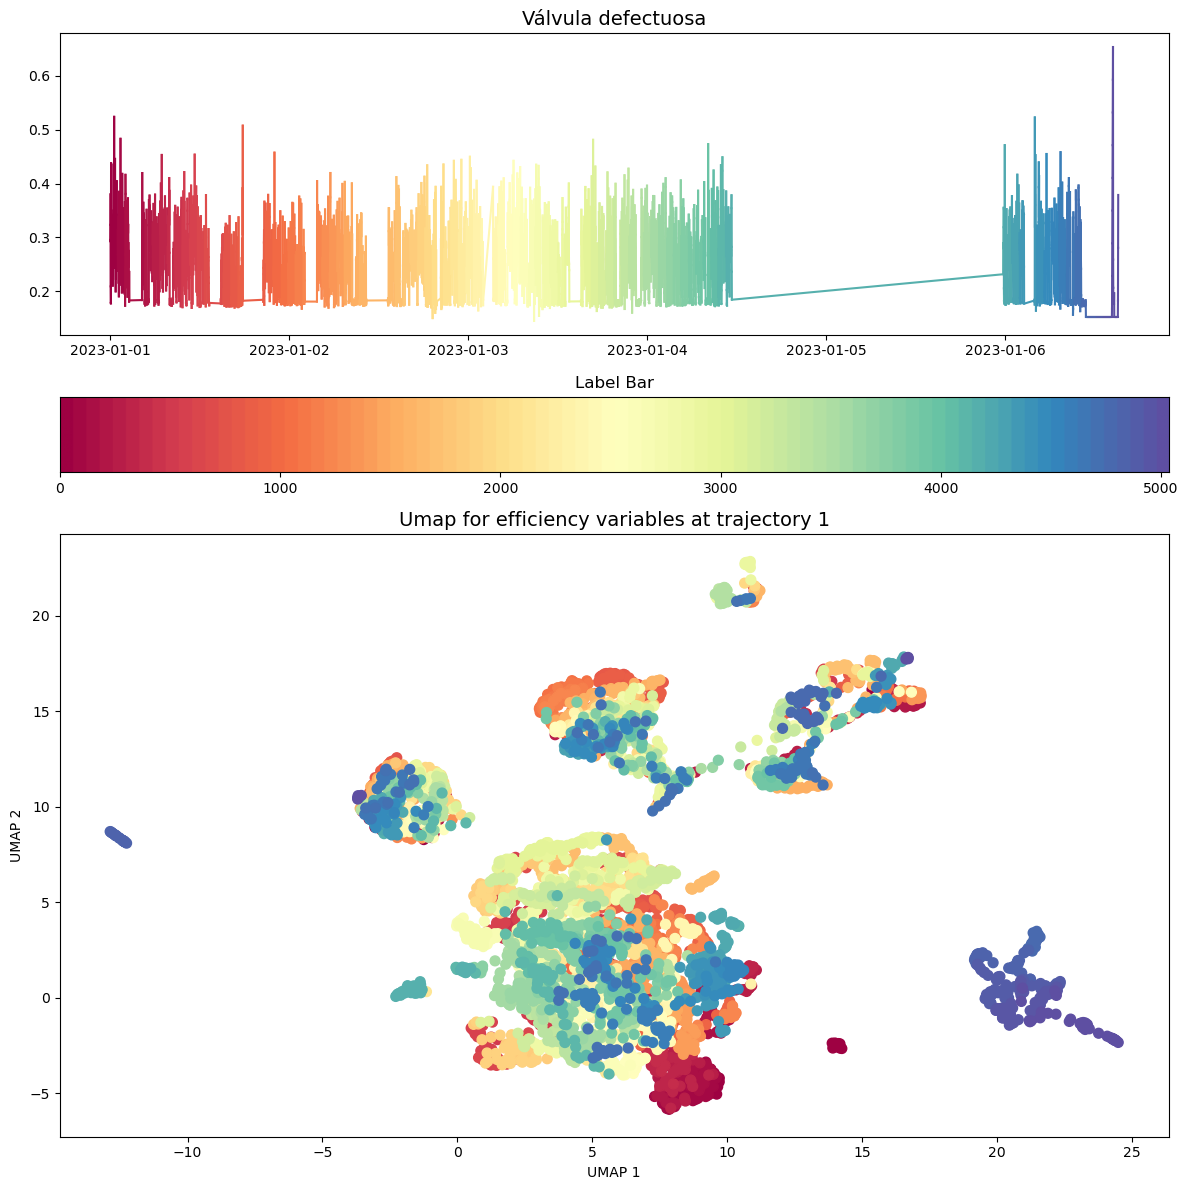

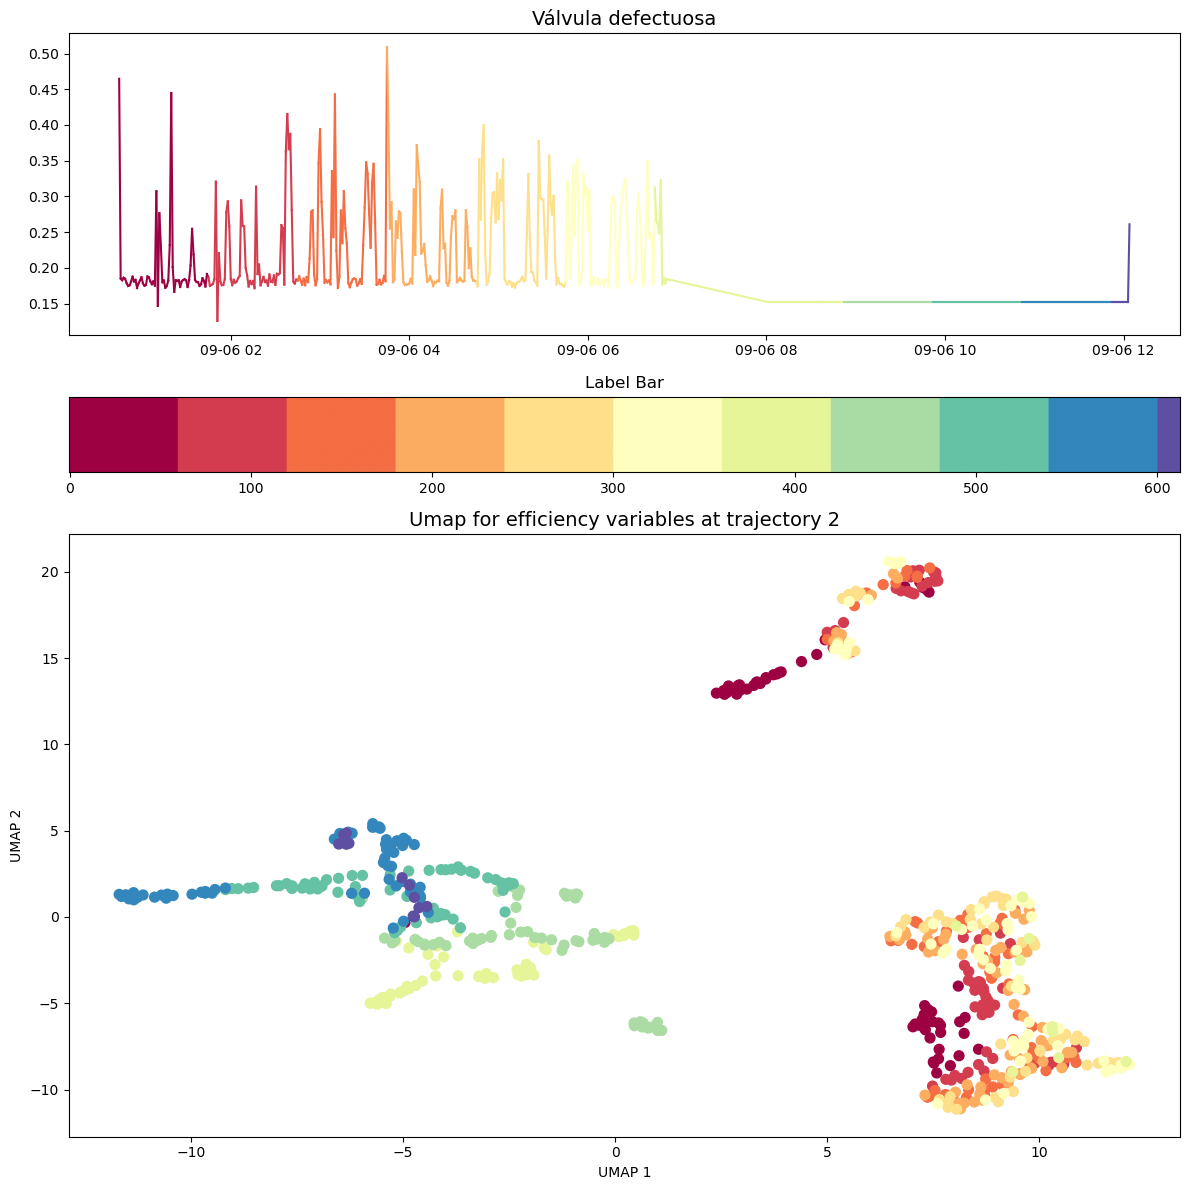

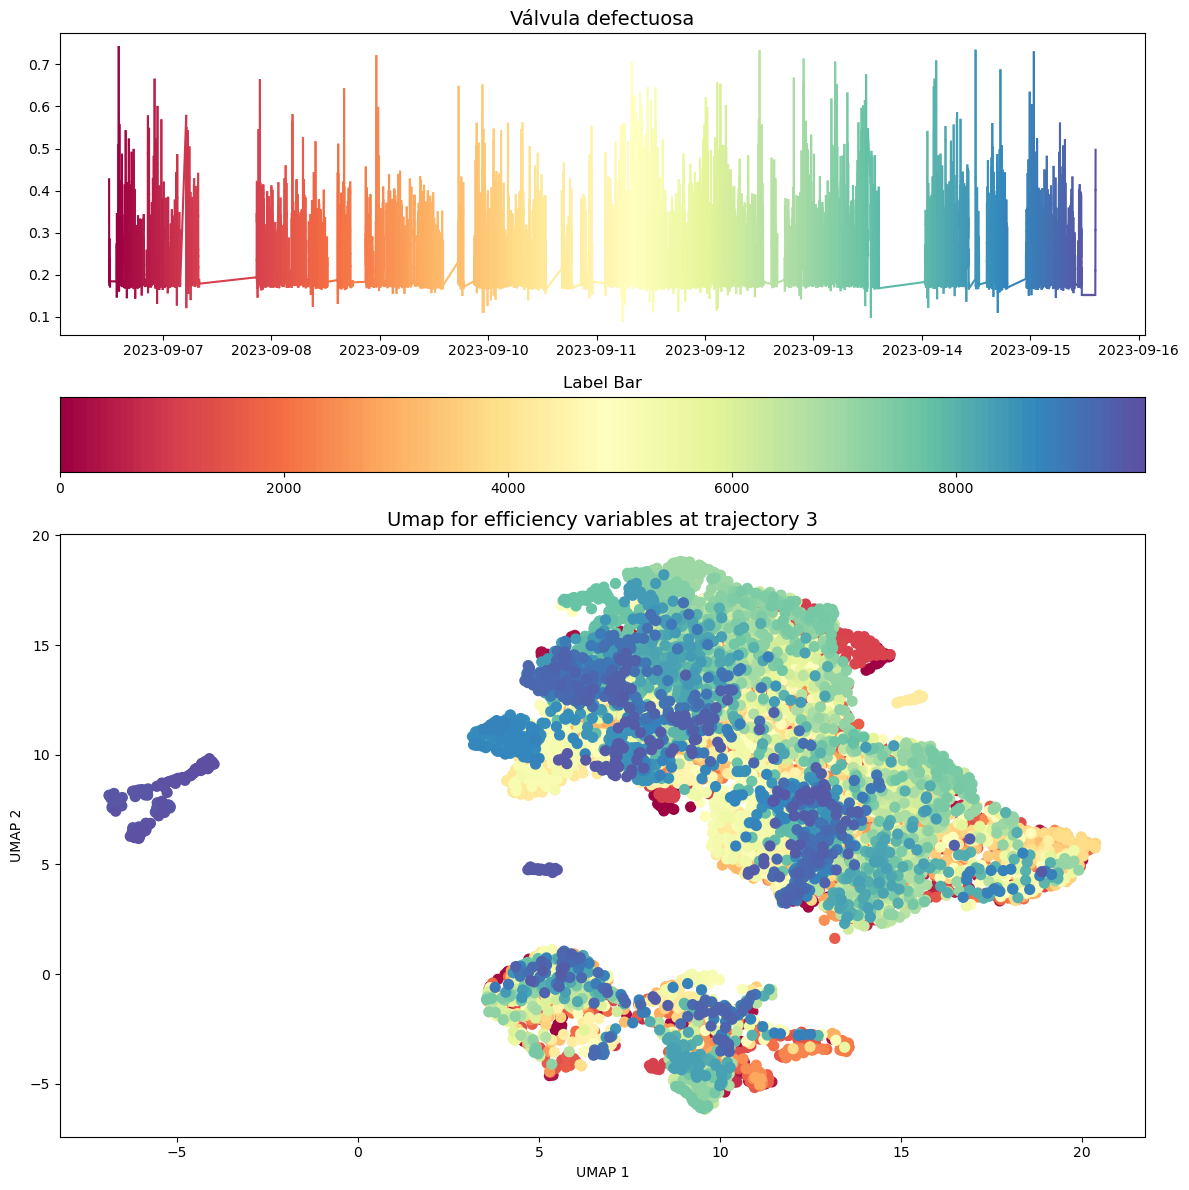

The MOF Falta de aceite hidráulico


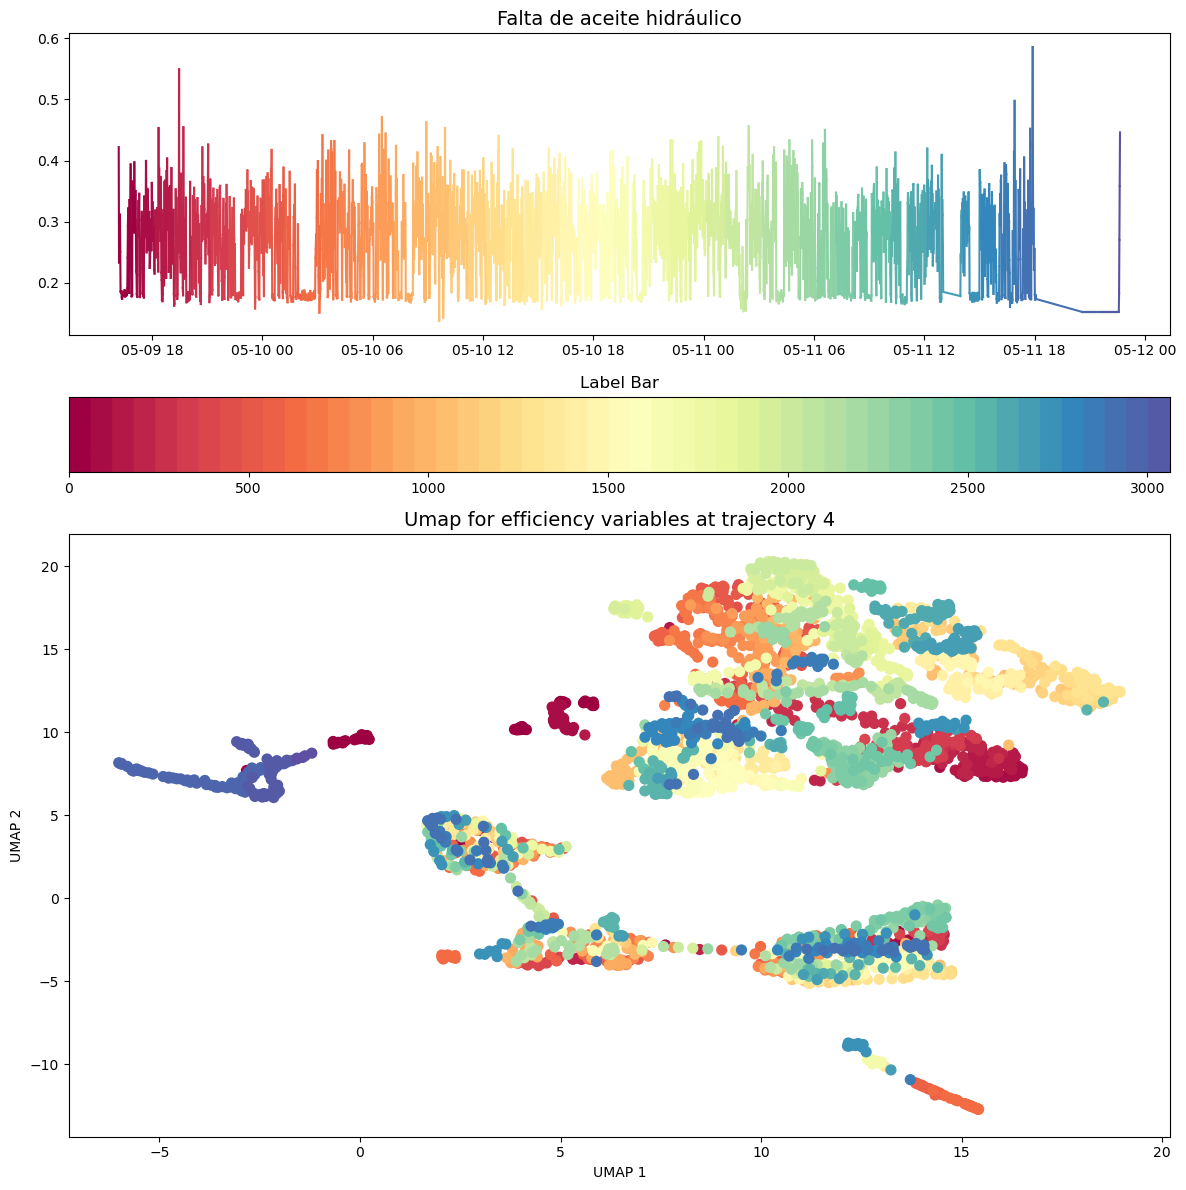

The MOF Lubricación  deficiente


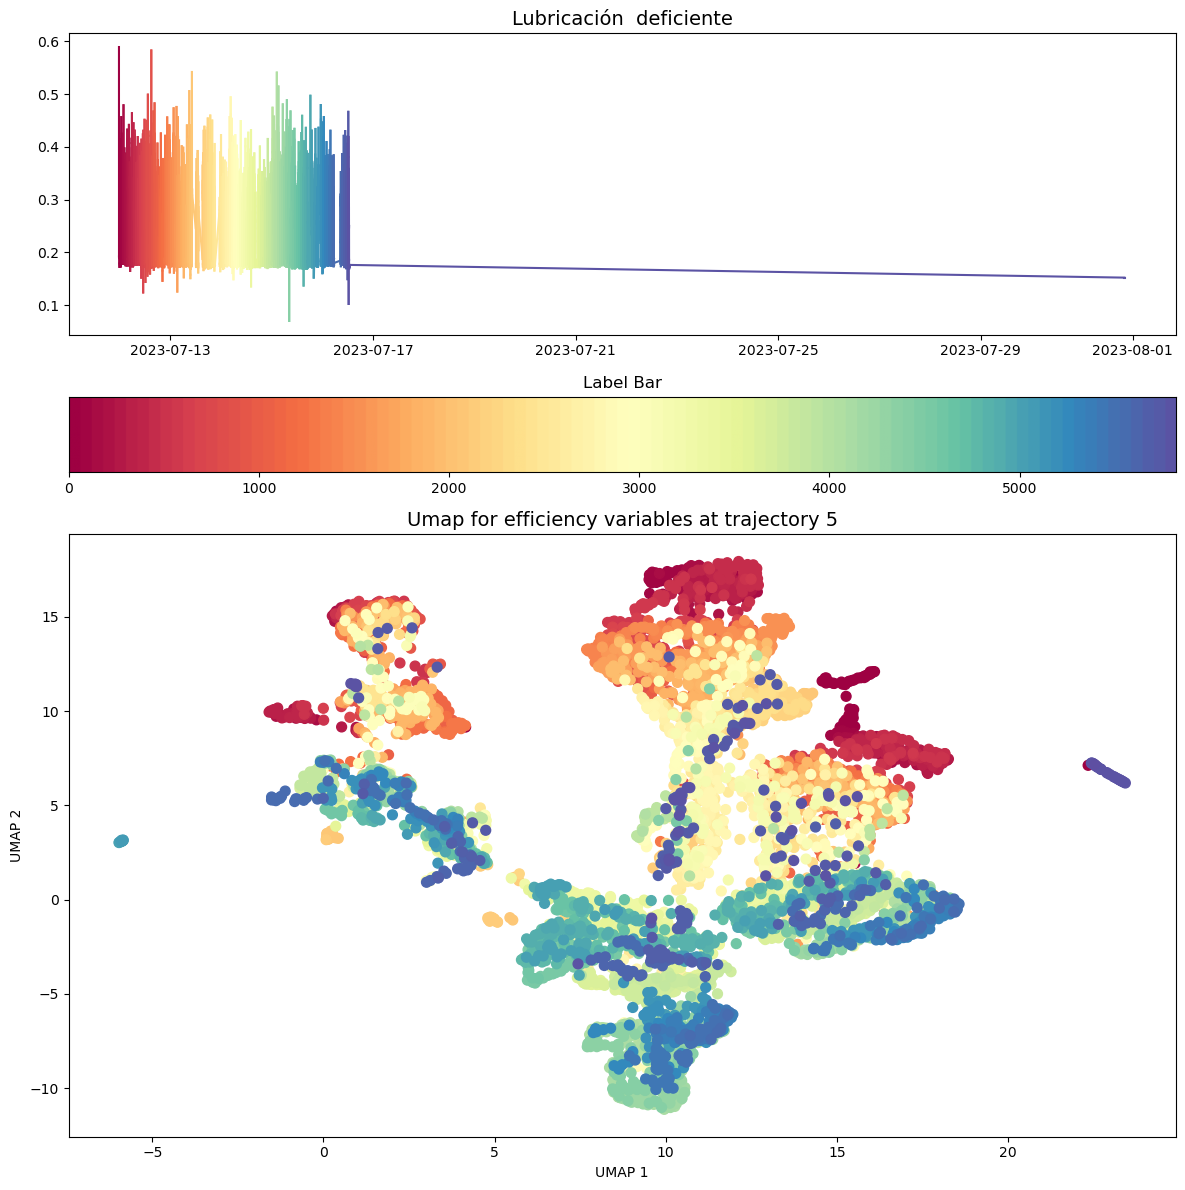

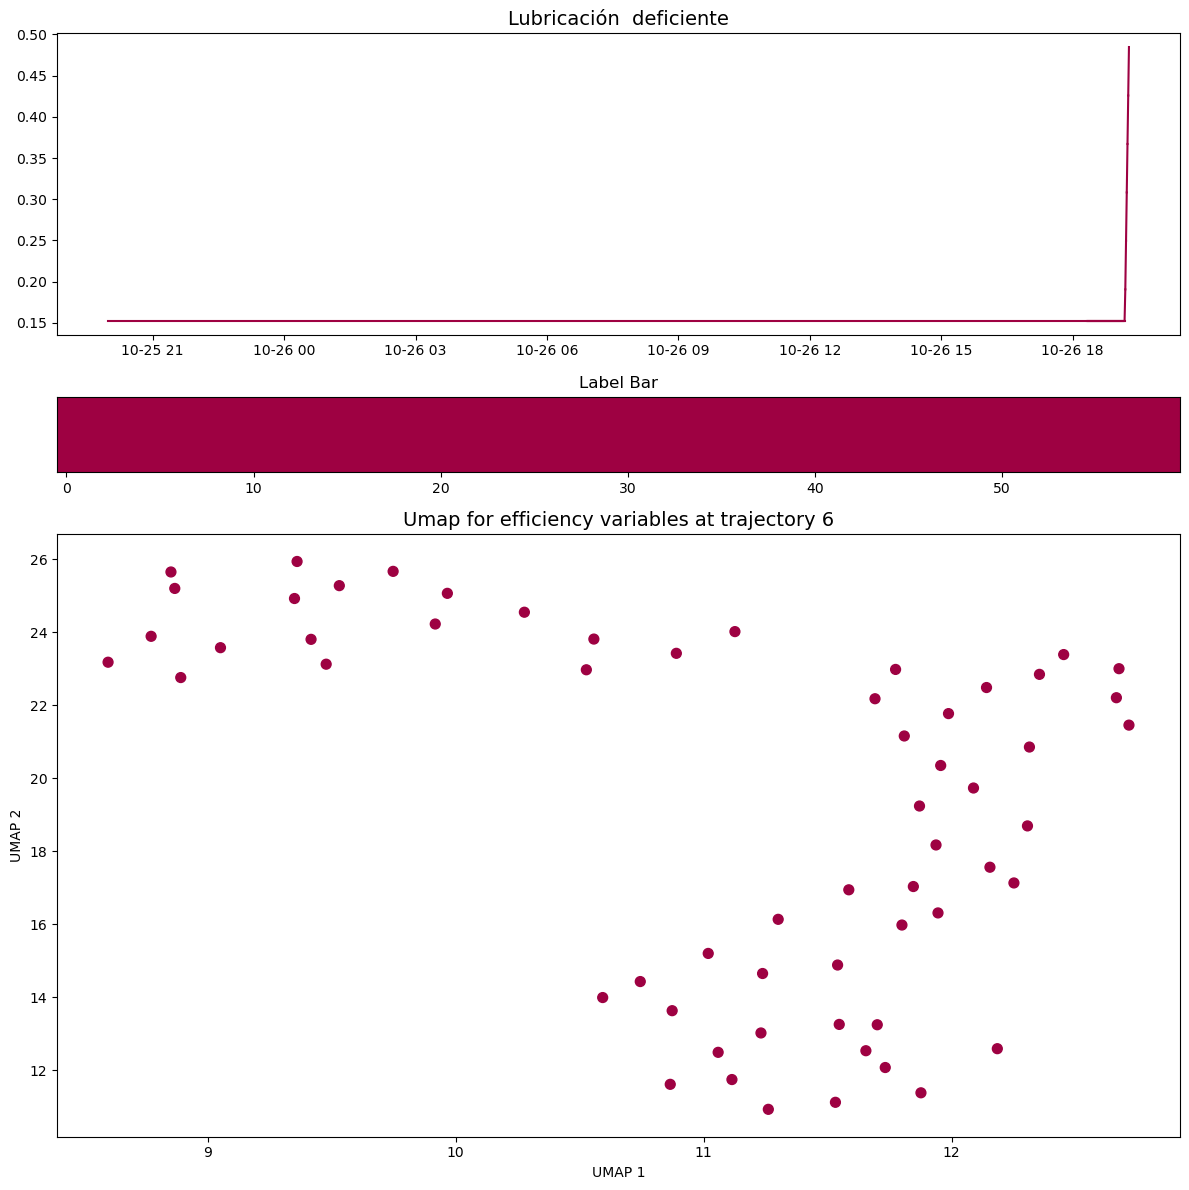

The MOF Temperatura fuera de rango


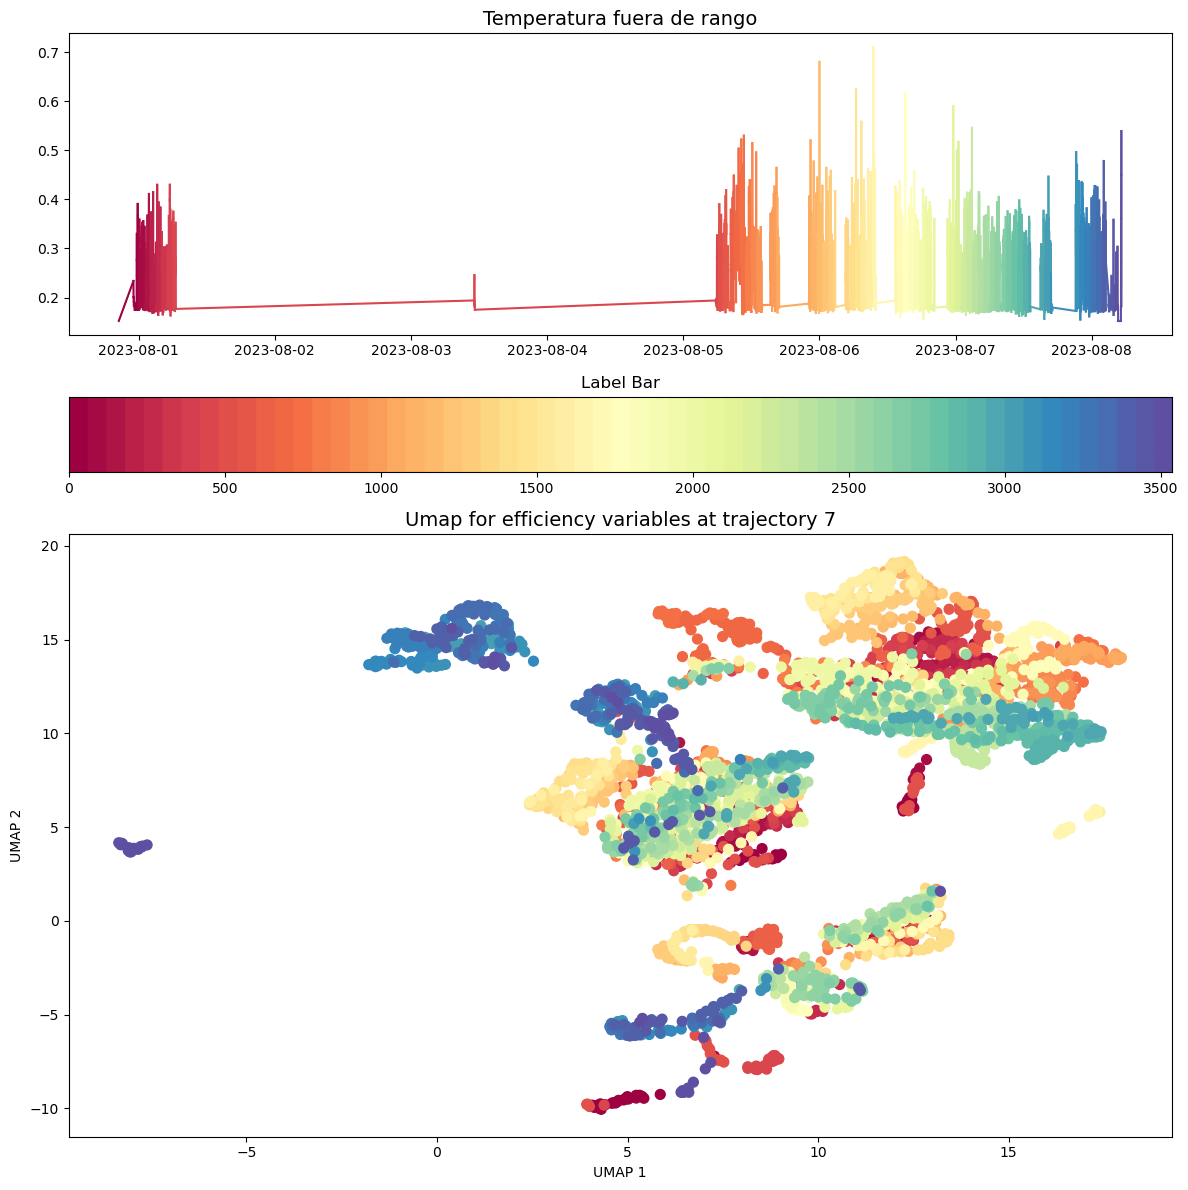

The MOF Bomba hidráulica con fuga


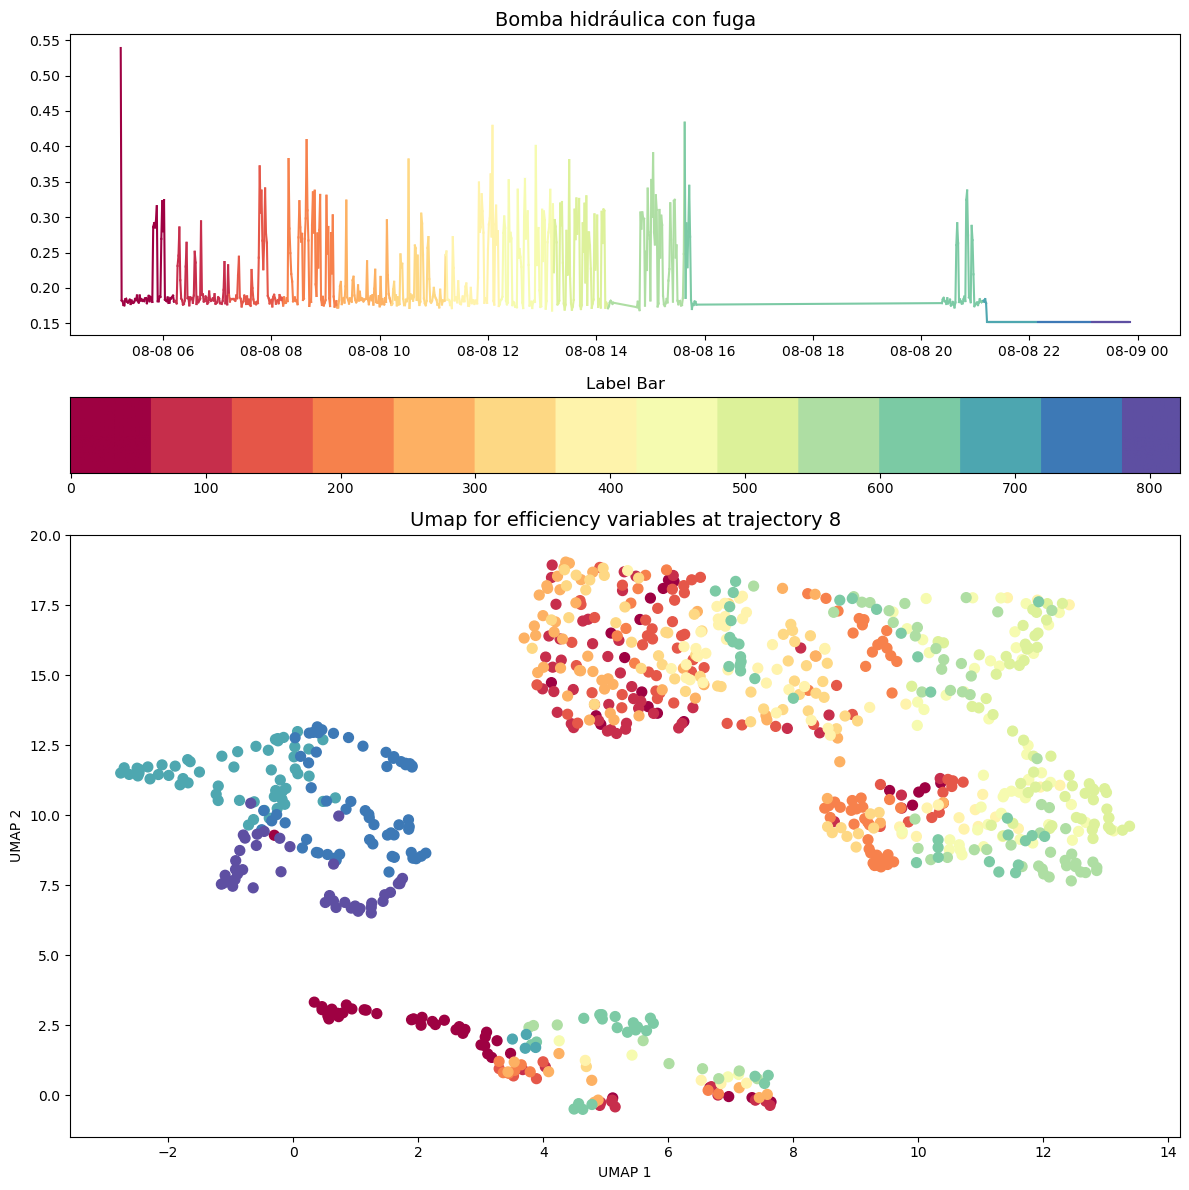

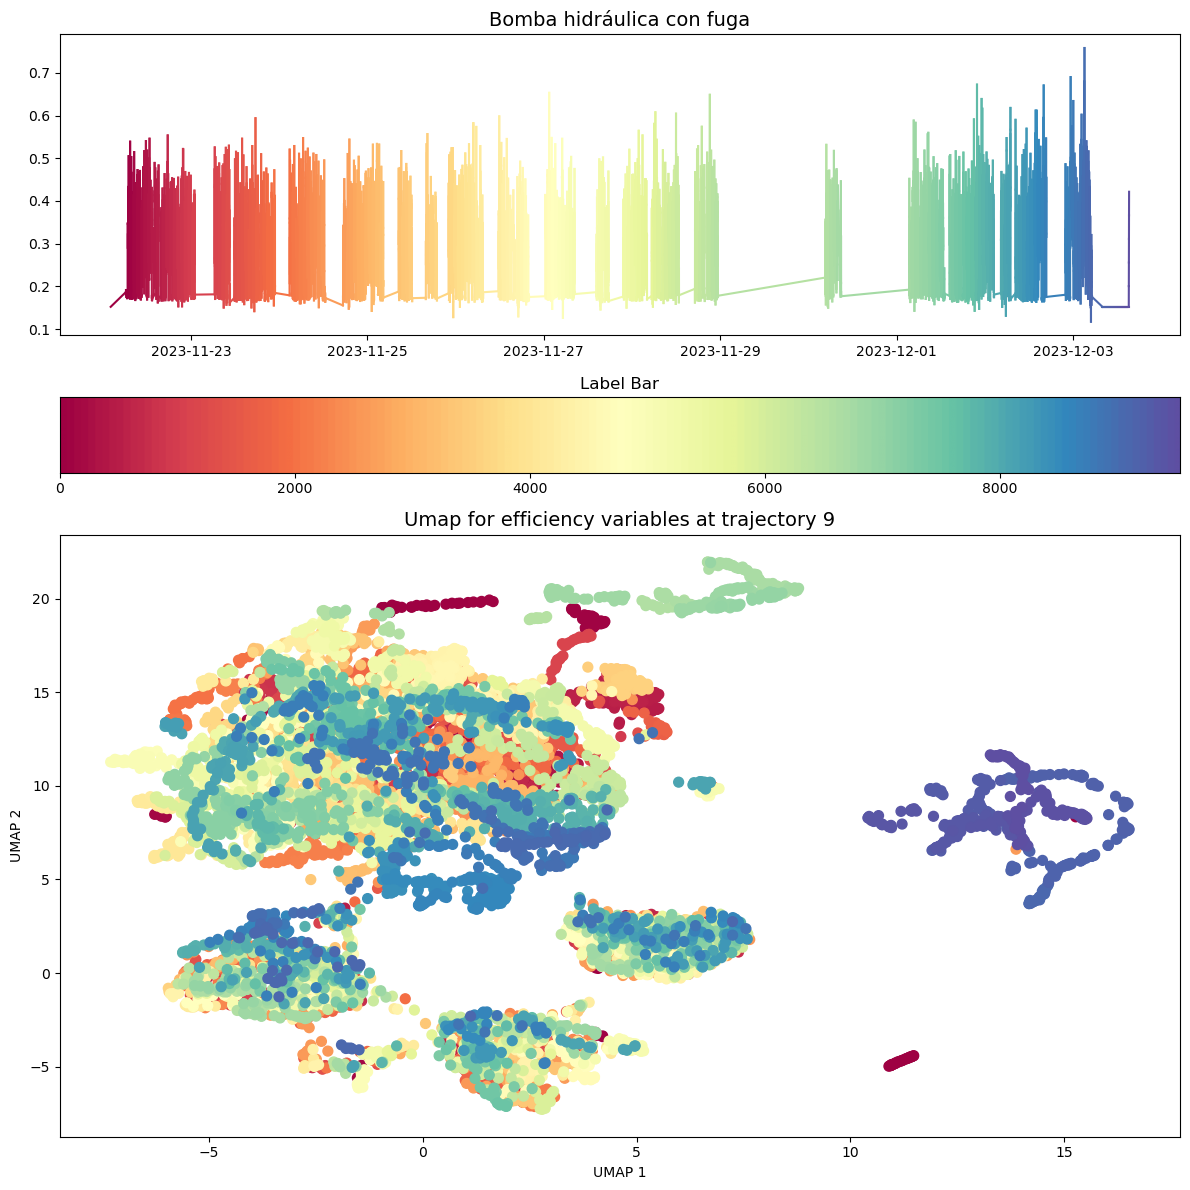

The MOF Fuga de aceite


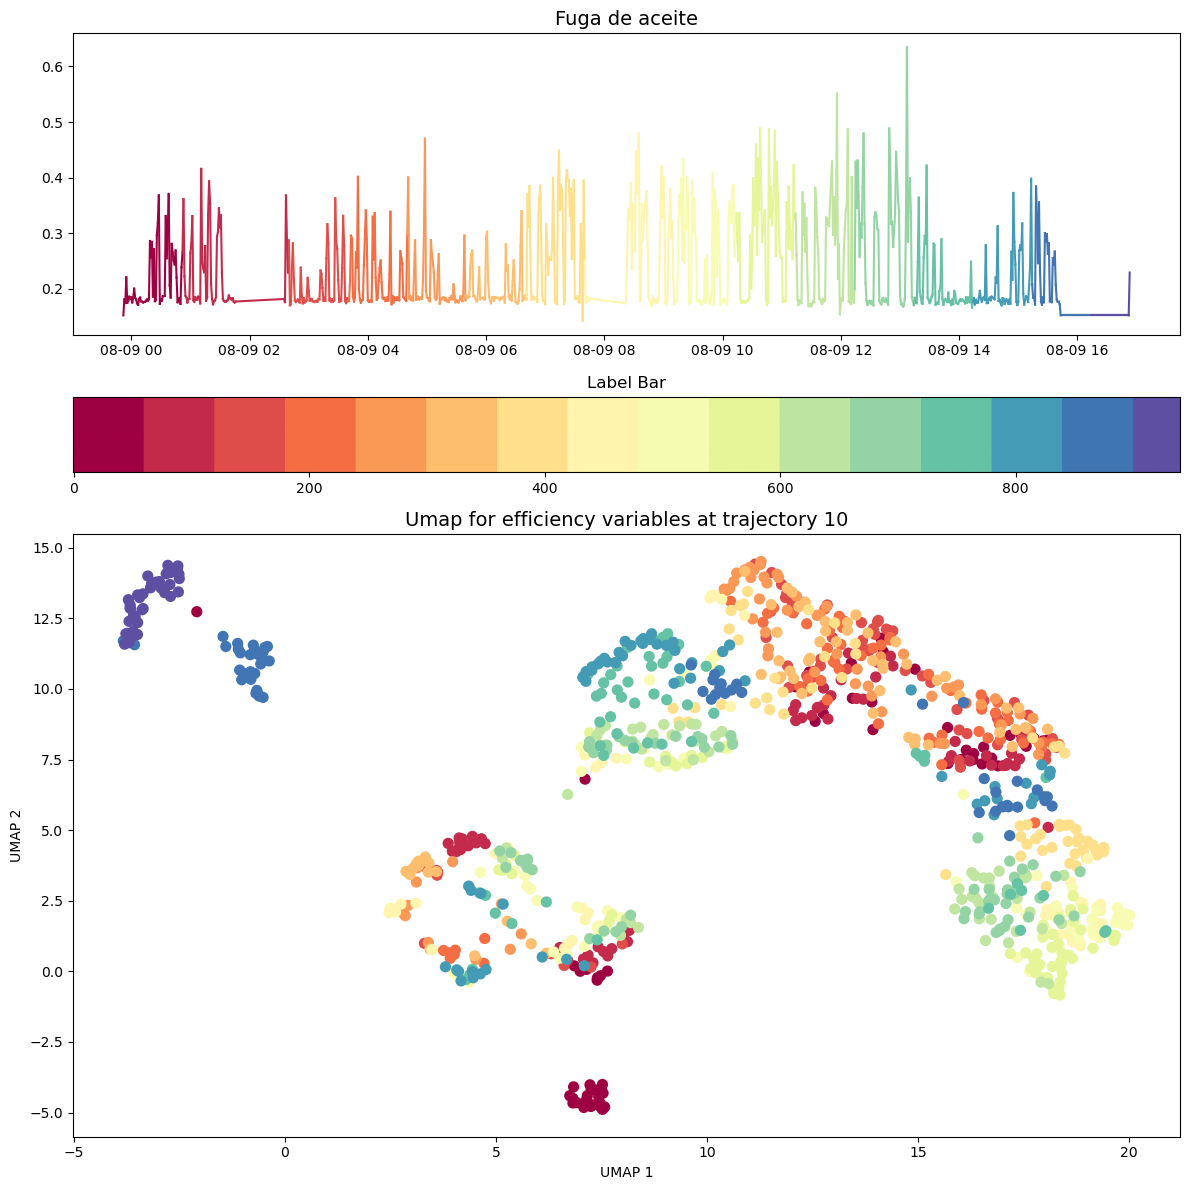

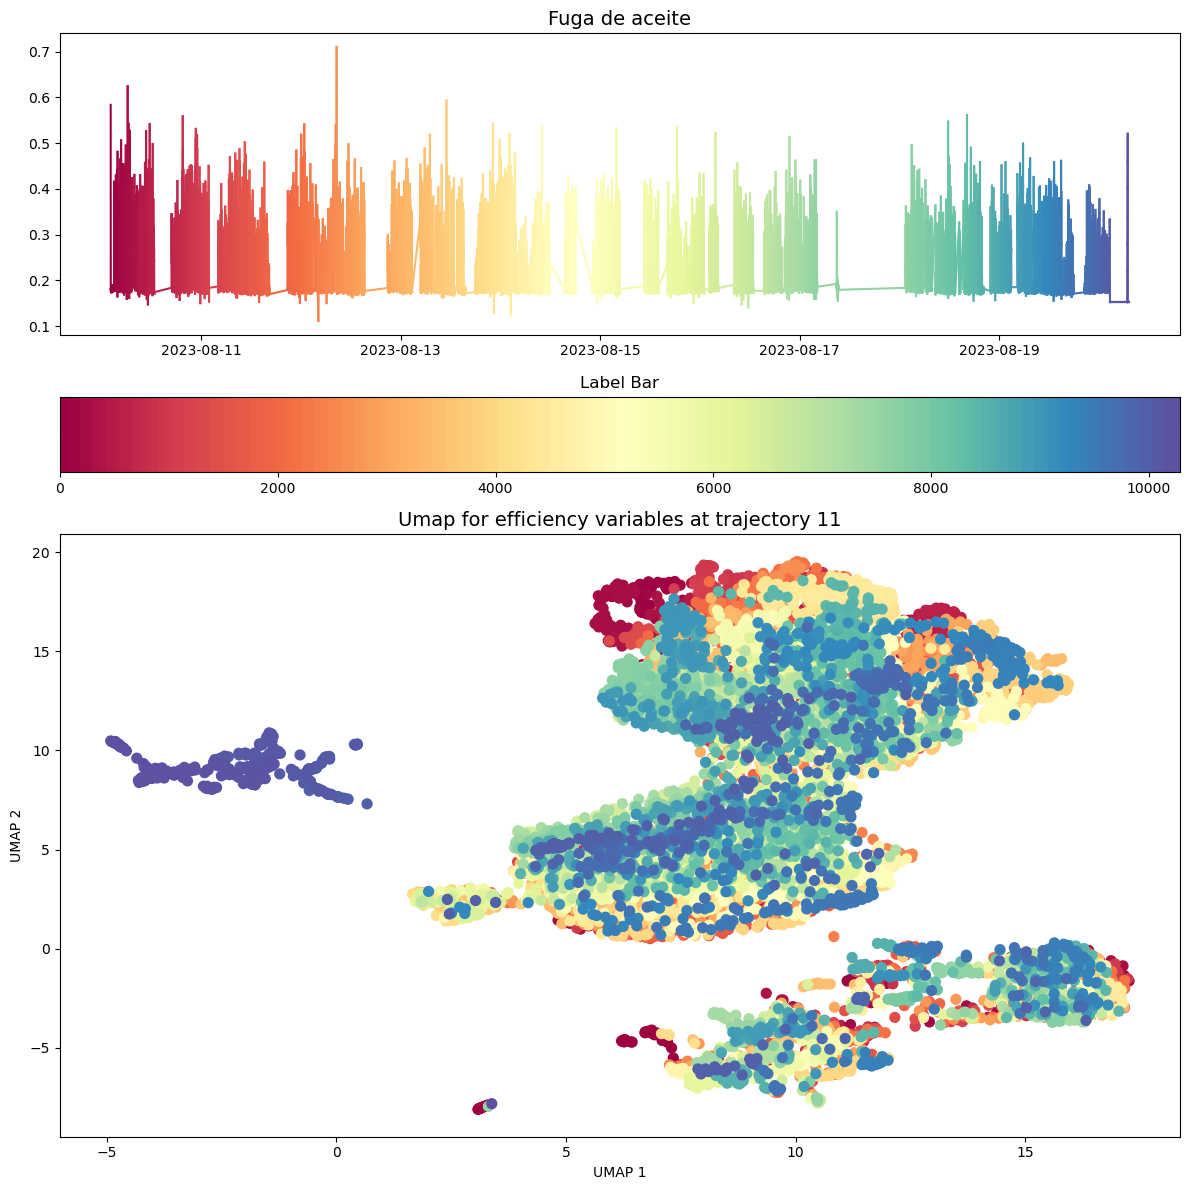

The MOF Falla sistema de hidroset-poste


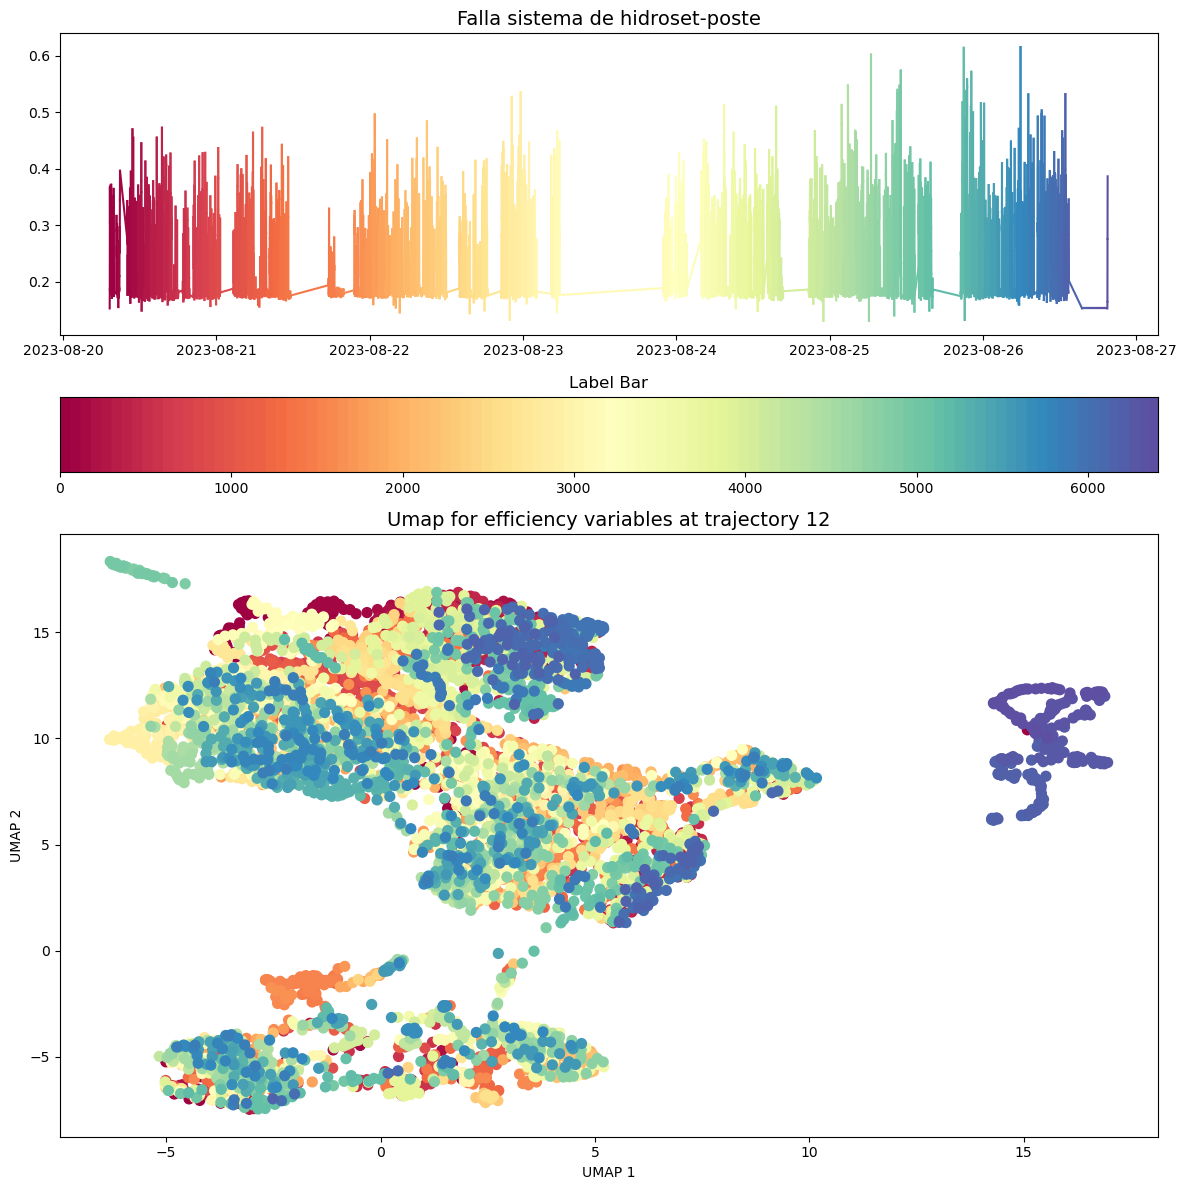

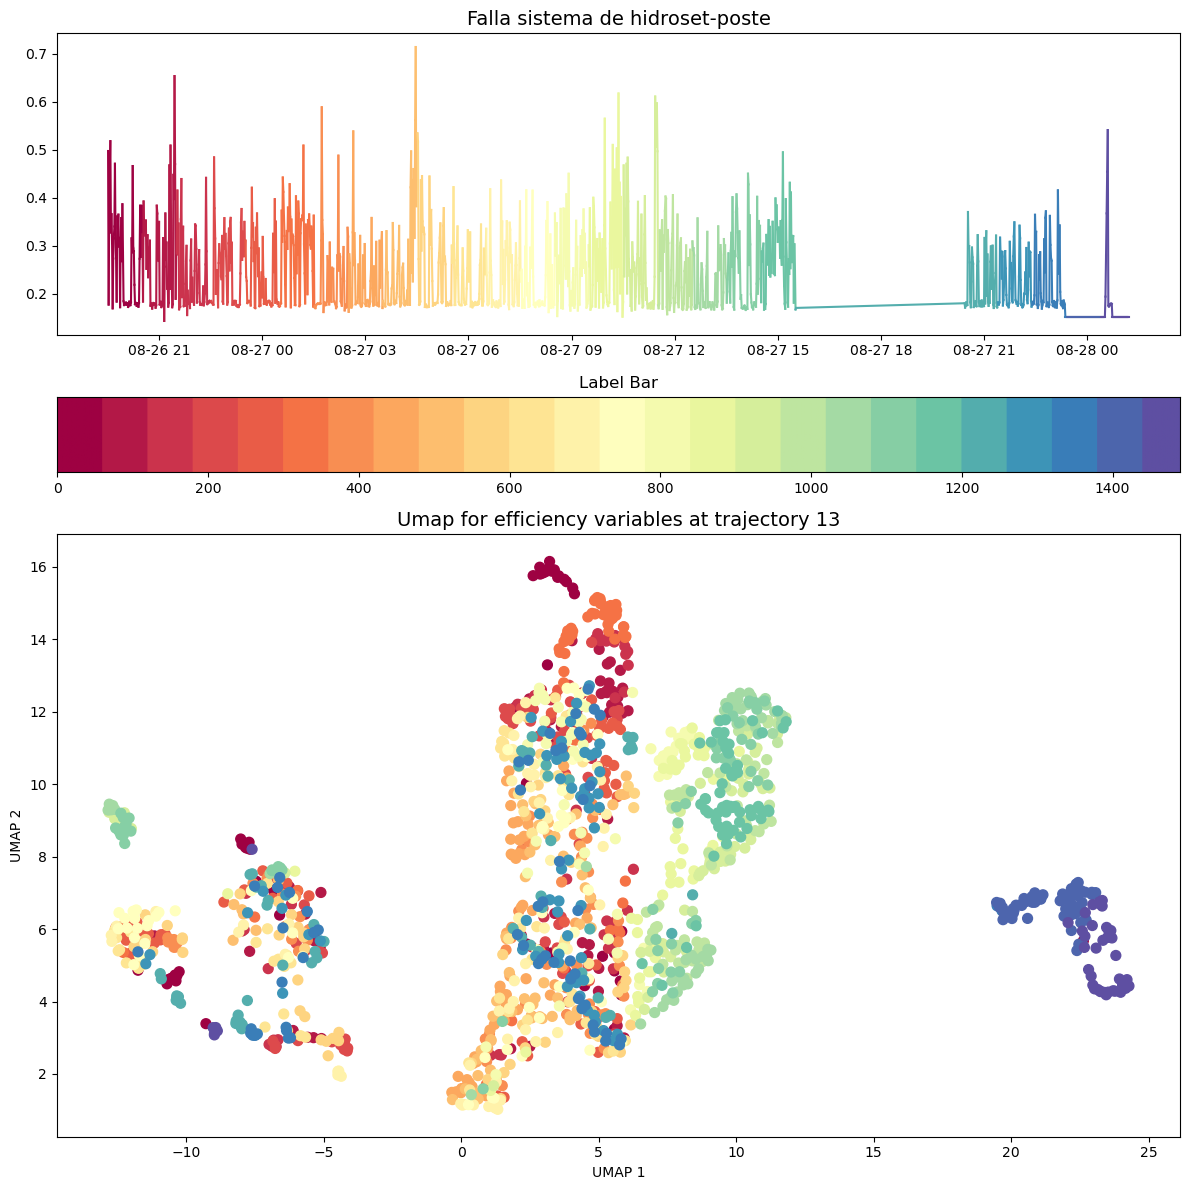

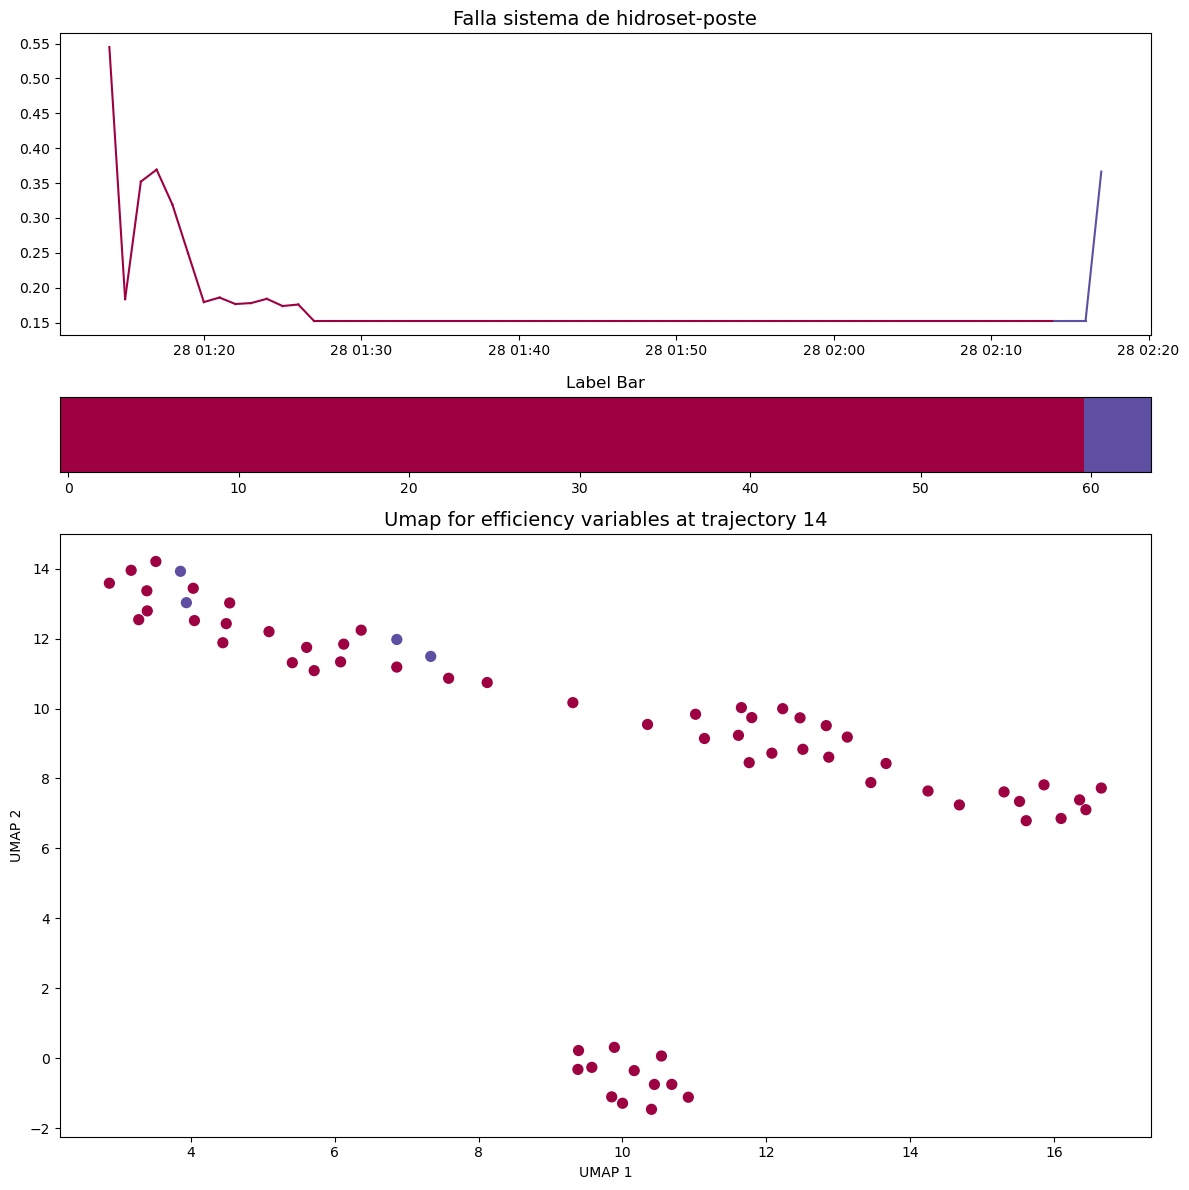

The MOF Mandibulas o revestimiento suelto


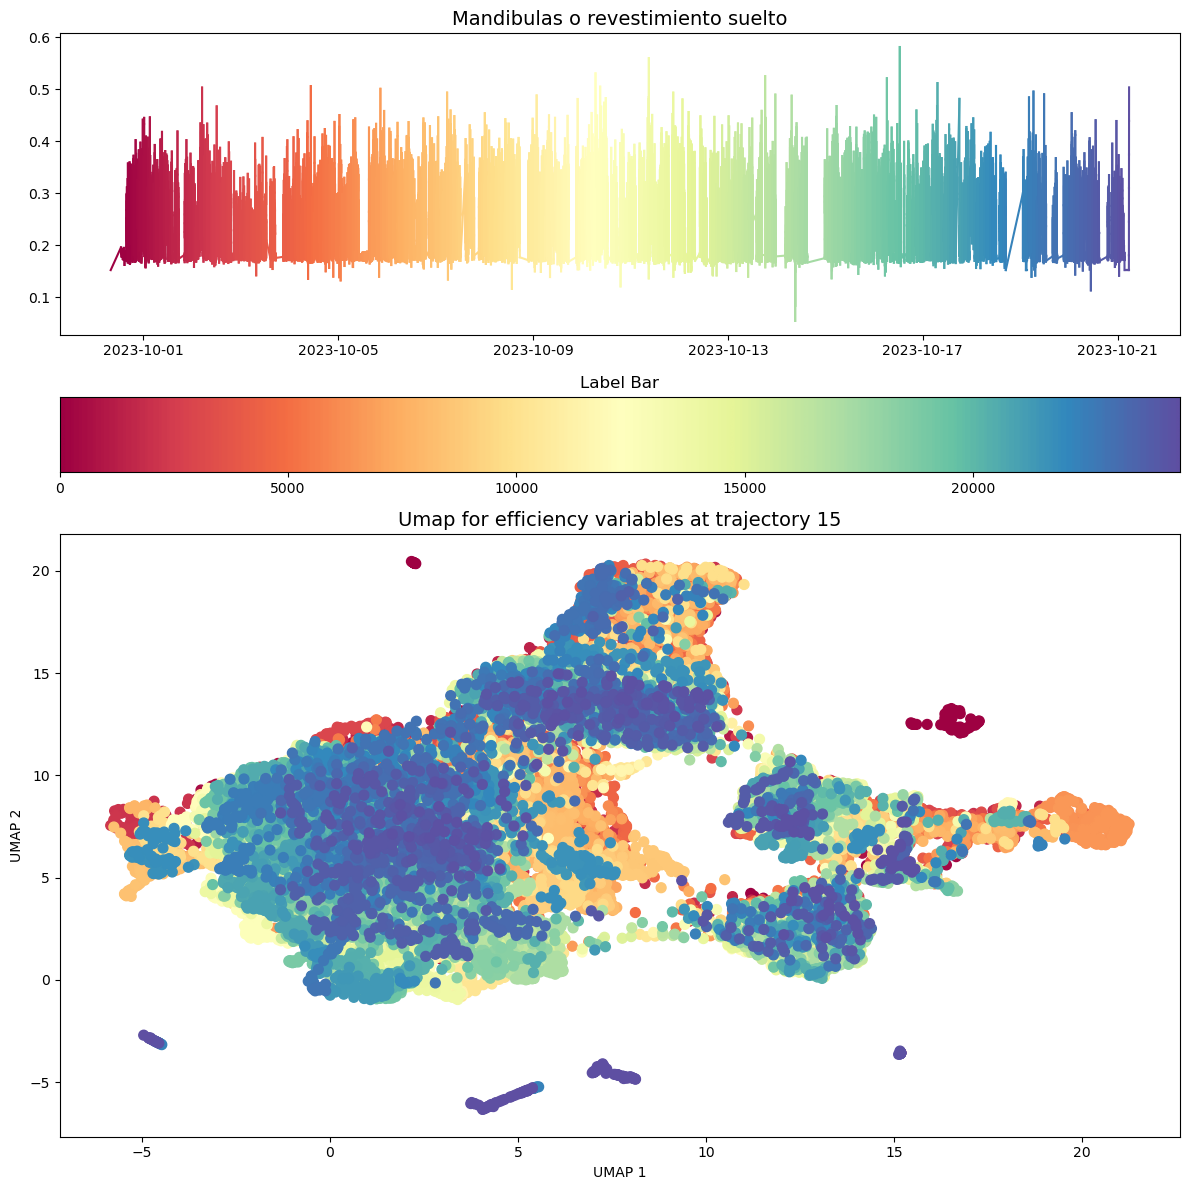

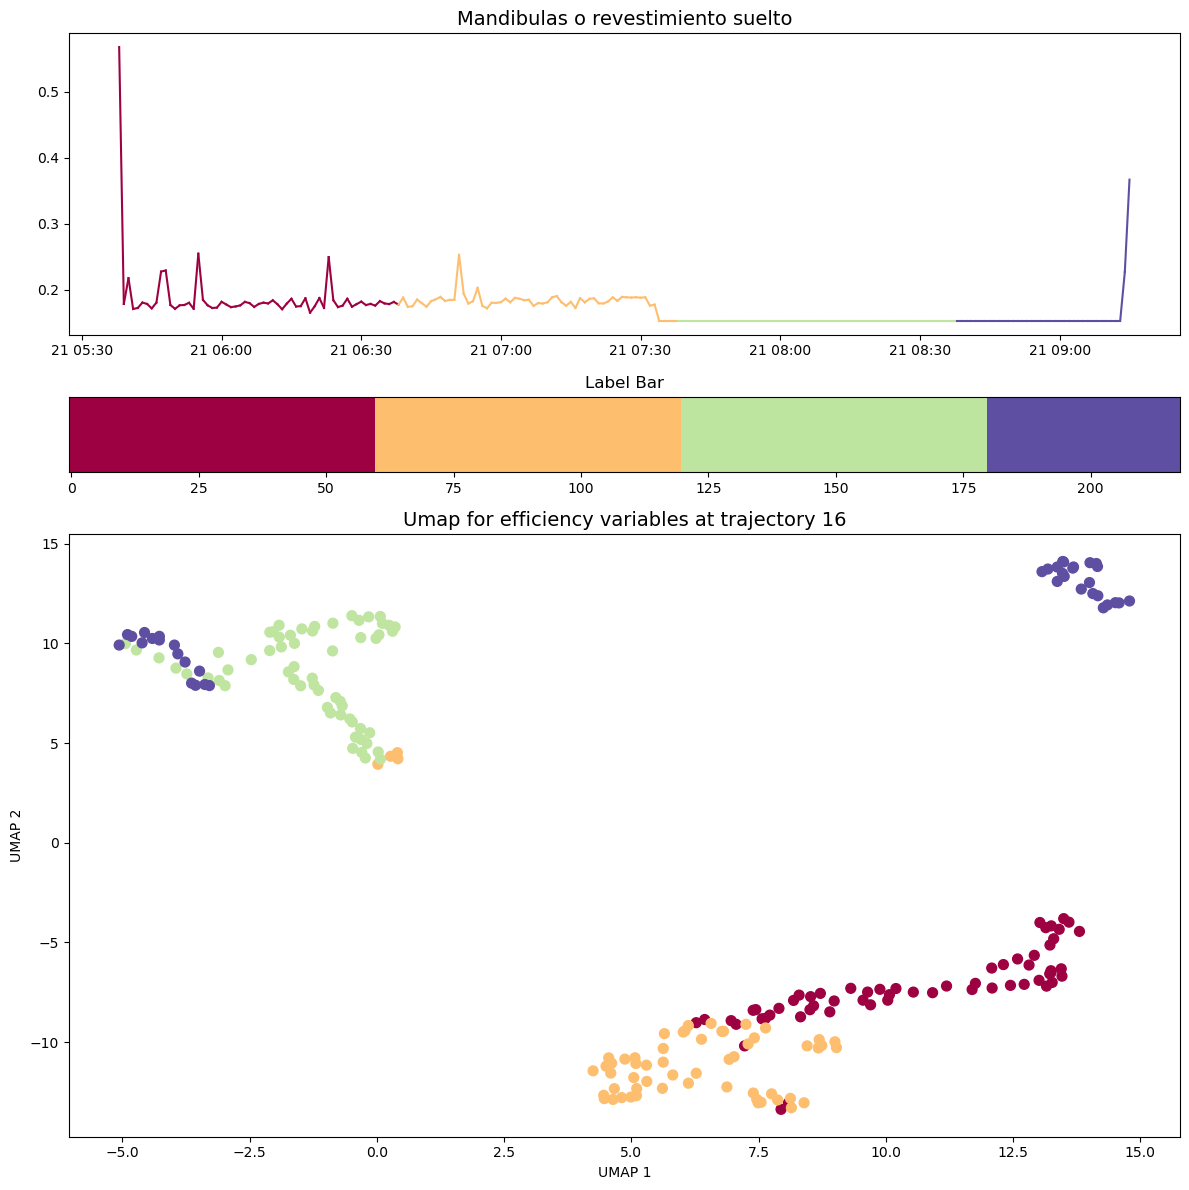

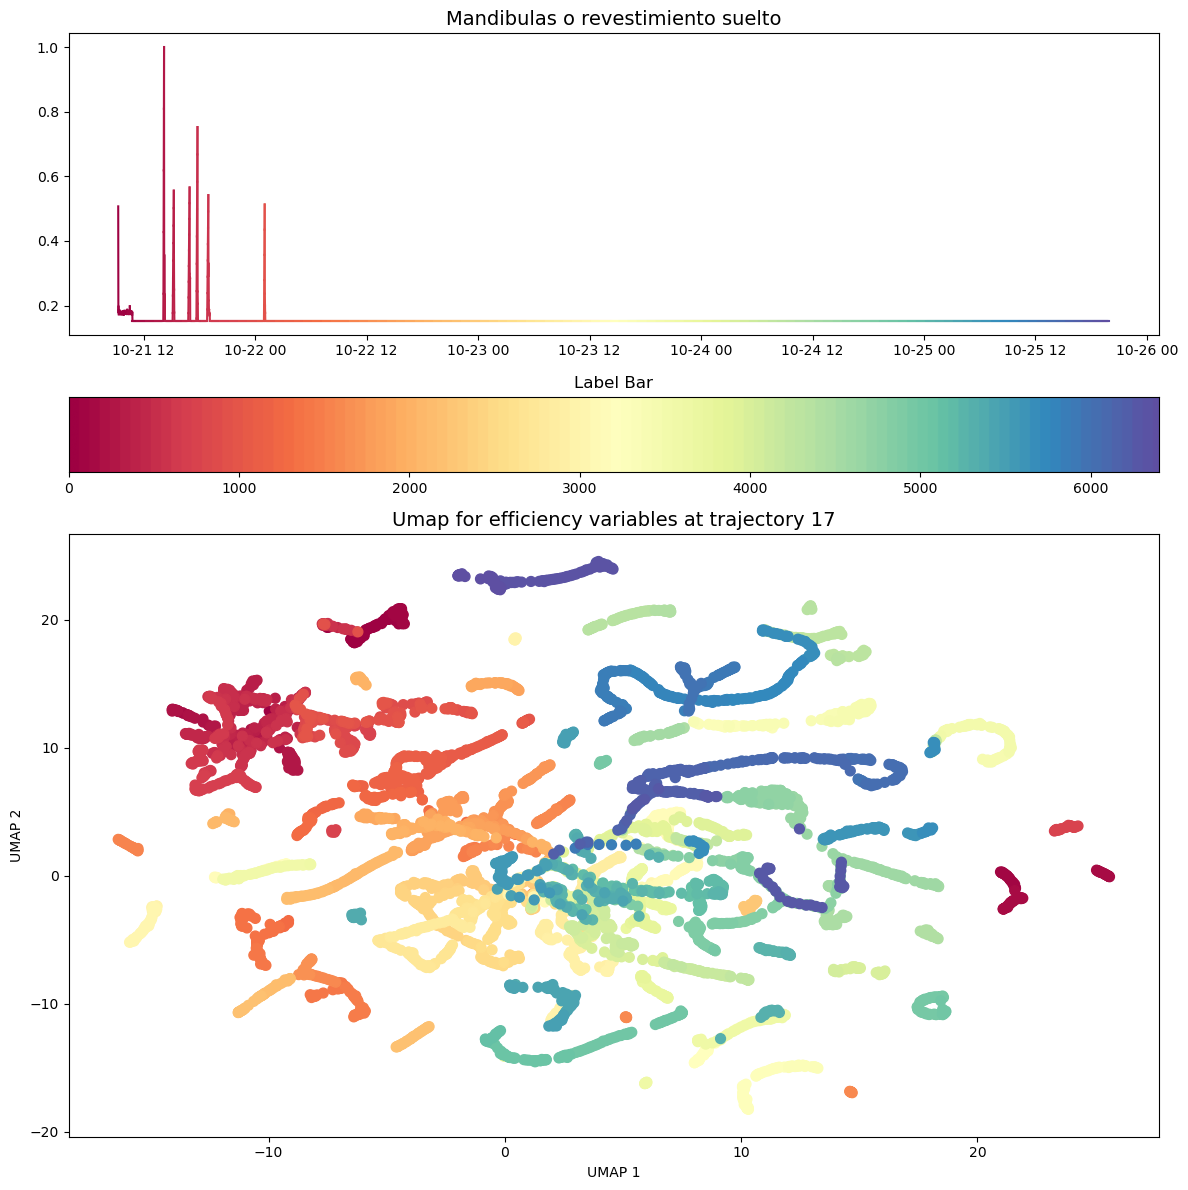

In [5]:
# sizeEachState       = 900 # 15 hours = 900min, or 60 min
sizeEachState       = 60
curTrajectory       = 0
for mof, idxTrajectList in trajectory.items():
    print(f"The MOF {mof}")
    for curTraject in idxTrajectList:

        lengthData = len(curTraject)
        # if lengthData >= 1440:
        #     sizeEachState   = 720
        # elif lengthData > 720:
        #     sizeEachState   = 180
        # else:
        #     sizeEachState   = 60
        # -----------------------------
        # Generate the label for the UMAP
        # -----------------------------
        labels              = np.repeat(np.arange(1, (curTraject.shape[0] // sizeEachState) + 1), sizeEachState)
        num_full_groups     = curTraject.shape[0] // sizeEachState
        remainder           = curTraject.shape[0] % sizeEachState
        if (remainder) > 0:
            labels = np.concatenate([labels, np.full(remainder, num_full_groups + 1)])
        
        # -----------------------------
        # Transform the UMAP
        # -----------------------------
        efficiencyTraject   = curTraject[preData.efficiencyCr1 + preData.addEfficiencyCr1]     # Extract the 
        embedding           = dimReductionModels.fit_transform(efficiencyTraject)

        # -----------------------------
        # Plot
        # -----------------------------
        norm                    = Normalize(vmin=labels.min(), vmax=labels.max())
        colors                  = plt.cm.Spectral(norm(labels))
        fig, (ax1, ax2, ax3)    = plt.subplots(3, 1, figsize=(12, 12), gridspec_kw={'height_ratios': [1, 0.5, 4]})

        testSignal = curTraject["Potencia(kW)"]
        time       = curTraject["tiempo"]
        for i in range(len(testSignal) - 1):
            ax1.plot(time.iloc[i:i+2], testSignal[i:i+2], color=colors[i])

        ax1.set_title(mof, fontsize=14)
        
        ax2.imshow([colors], aspect='auto')
        ax2.set_yticks([])
        ax2.set_title('Label Bar')
        

        # Plot the UMAP projection
        scatter = ax3.scatter(embedding[:, 0], embedding[:, 1], c=labels, cmap='Spectral', s=50)
        # plt.colorbar(scatter, ax=ax3, label='Period Label')
        curTrajectory = curTrajectory + 1
        ax3.set_title(f'Umap for efficiency variables at trajectory {curTrajectory}', fontsize=14)
        ax3.set_xlabel('UMAP 1')
        ax3.set_ylabel('UMAP 2')

        plt.tight_layout()
        plt.show()




#### For manipulated variables

The MOF Válvula defectuosa


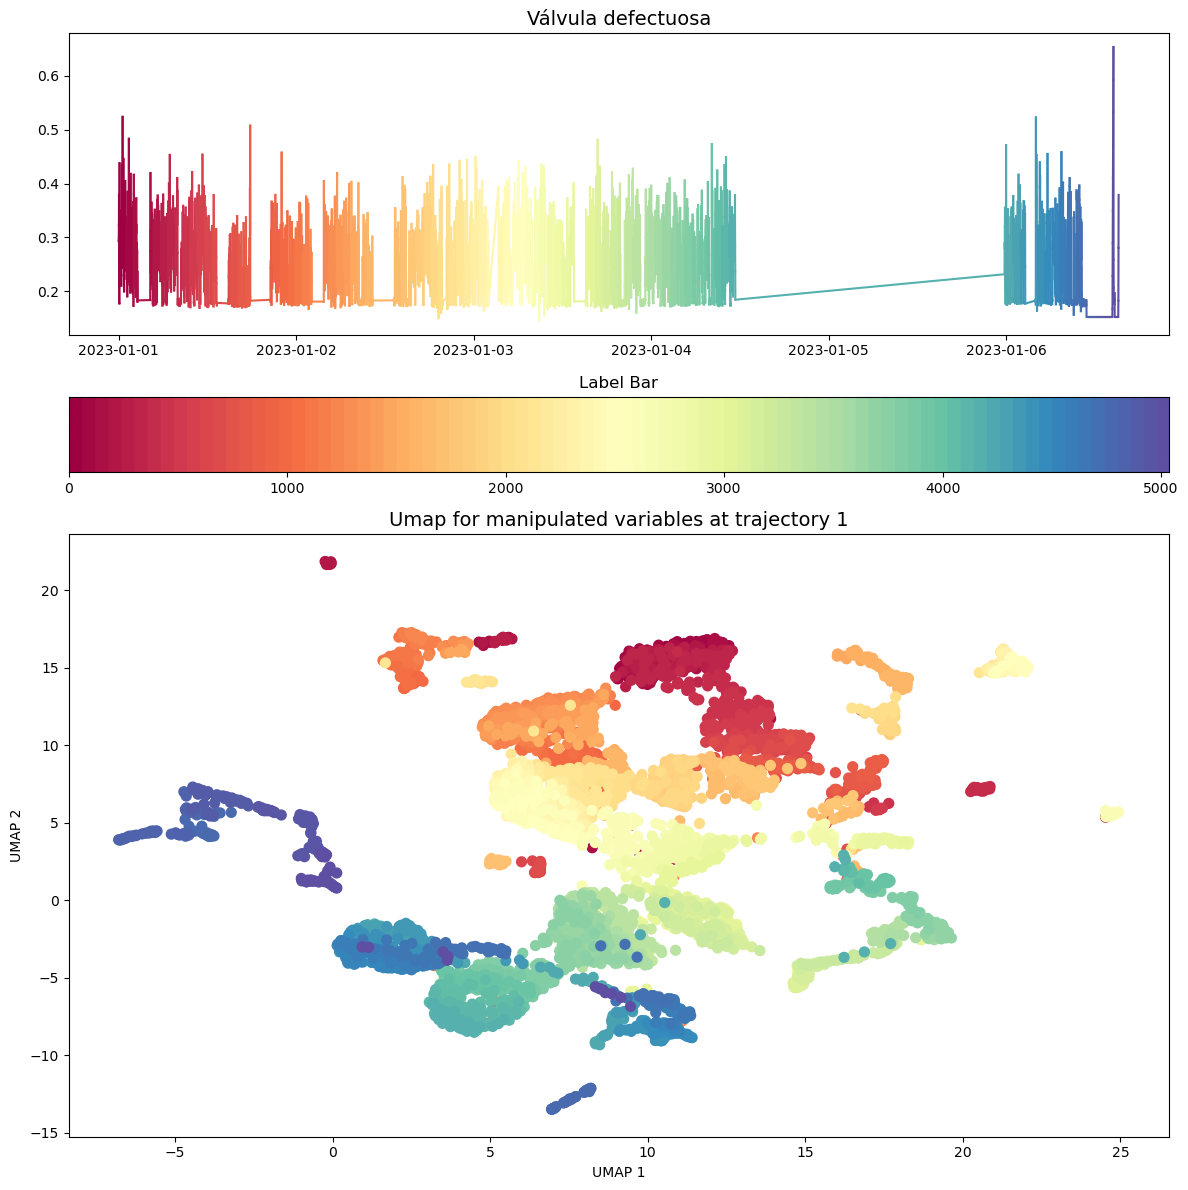

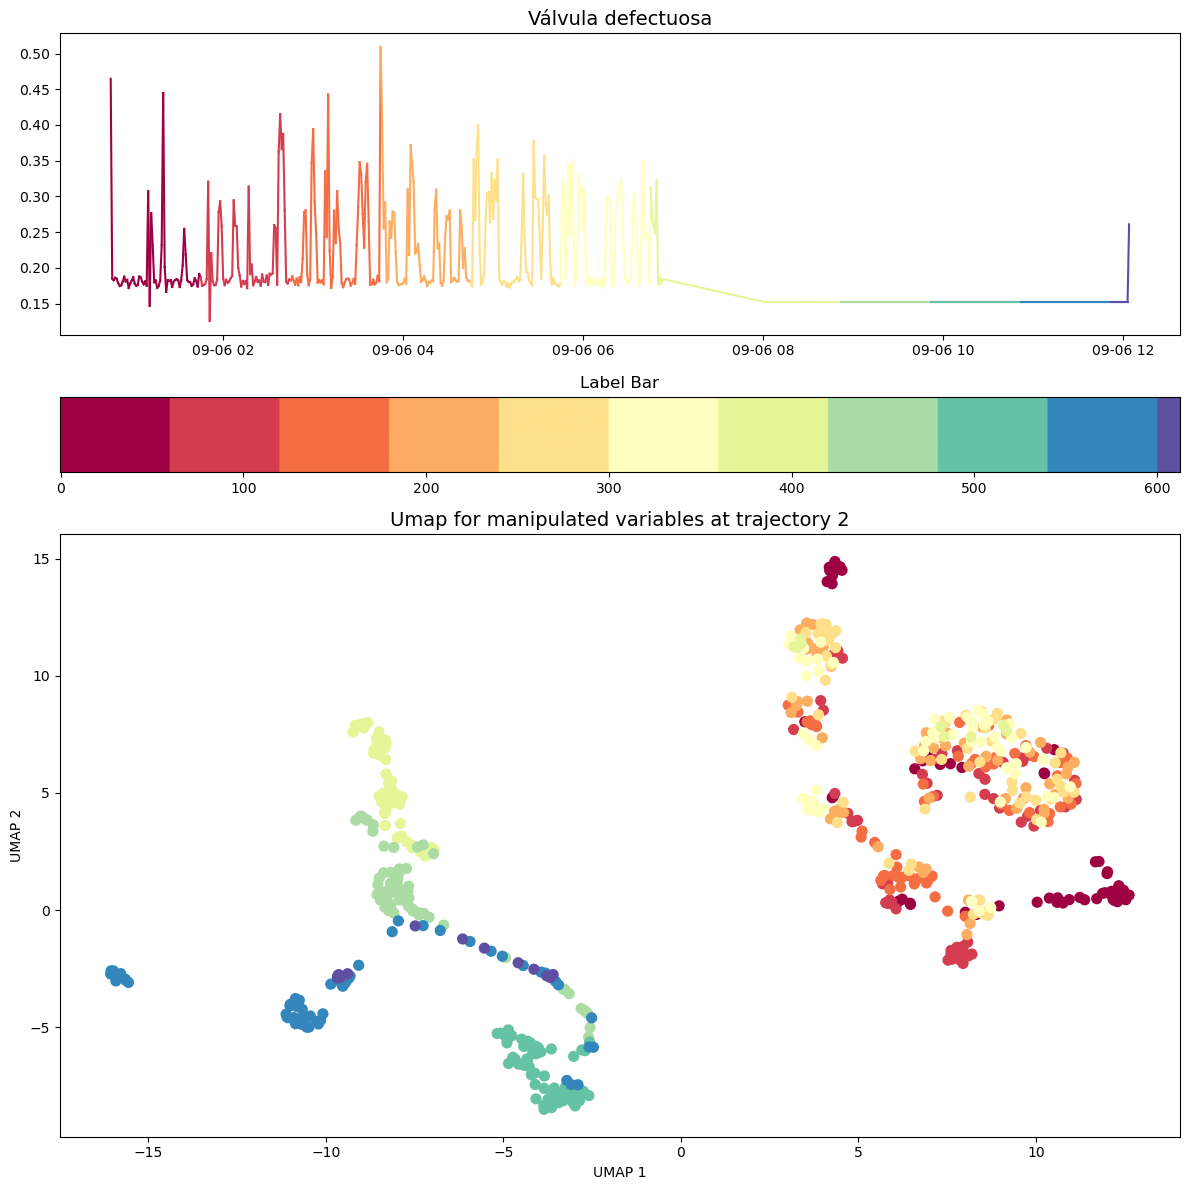

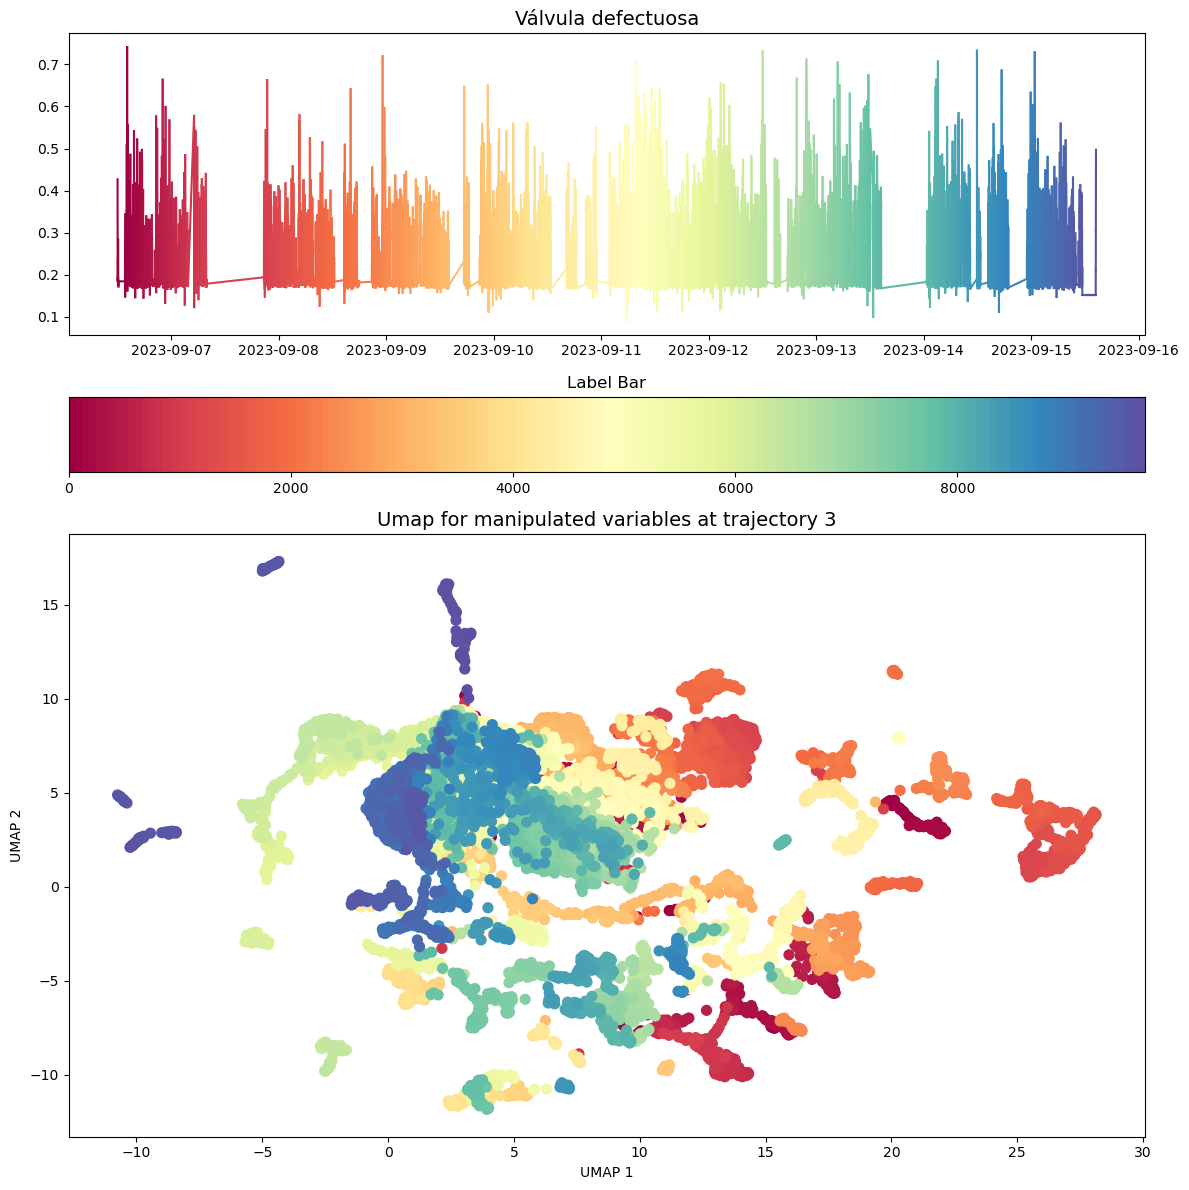

The MOF Falta de aceite hidráulico


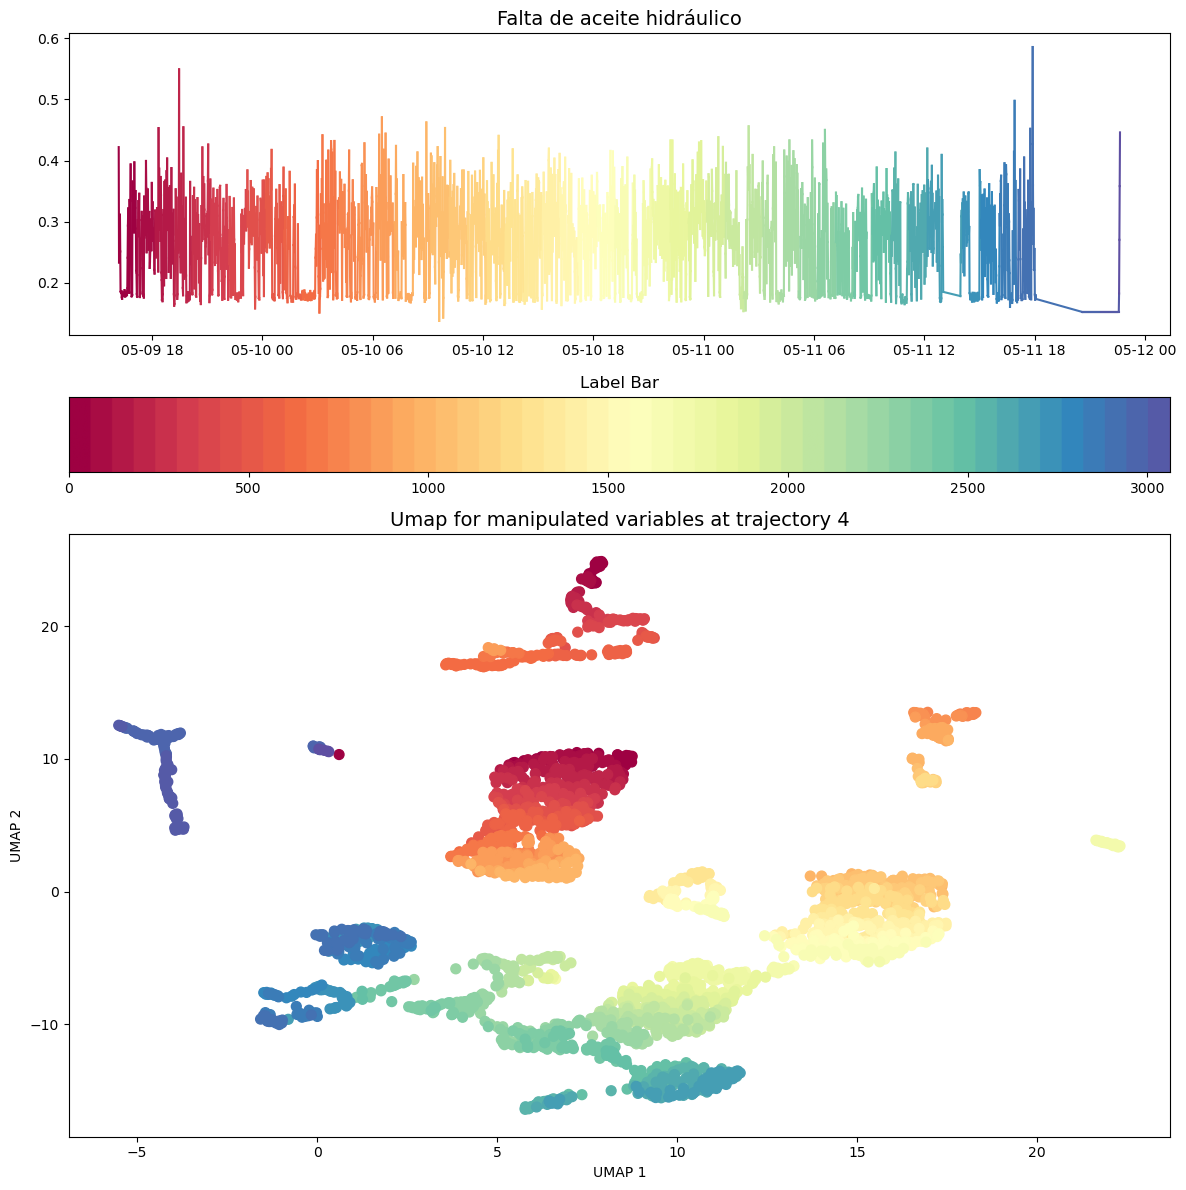

The MOF Lubricación  deficiente


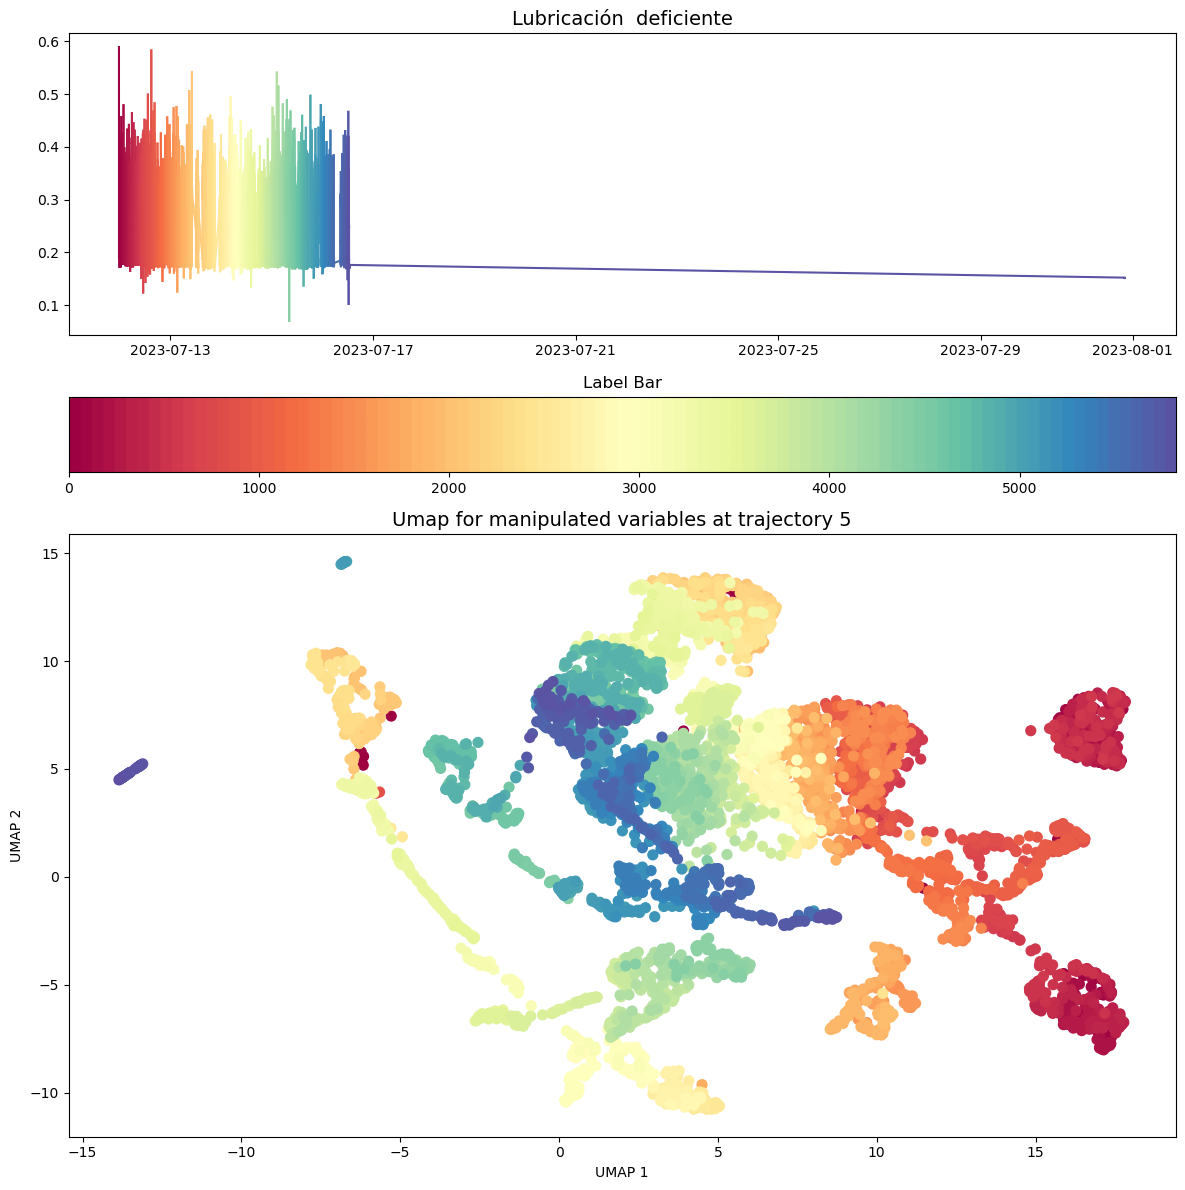

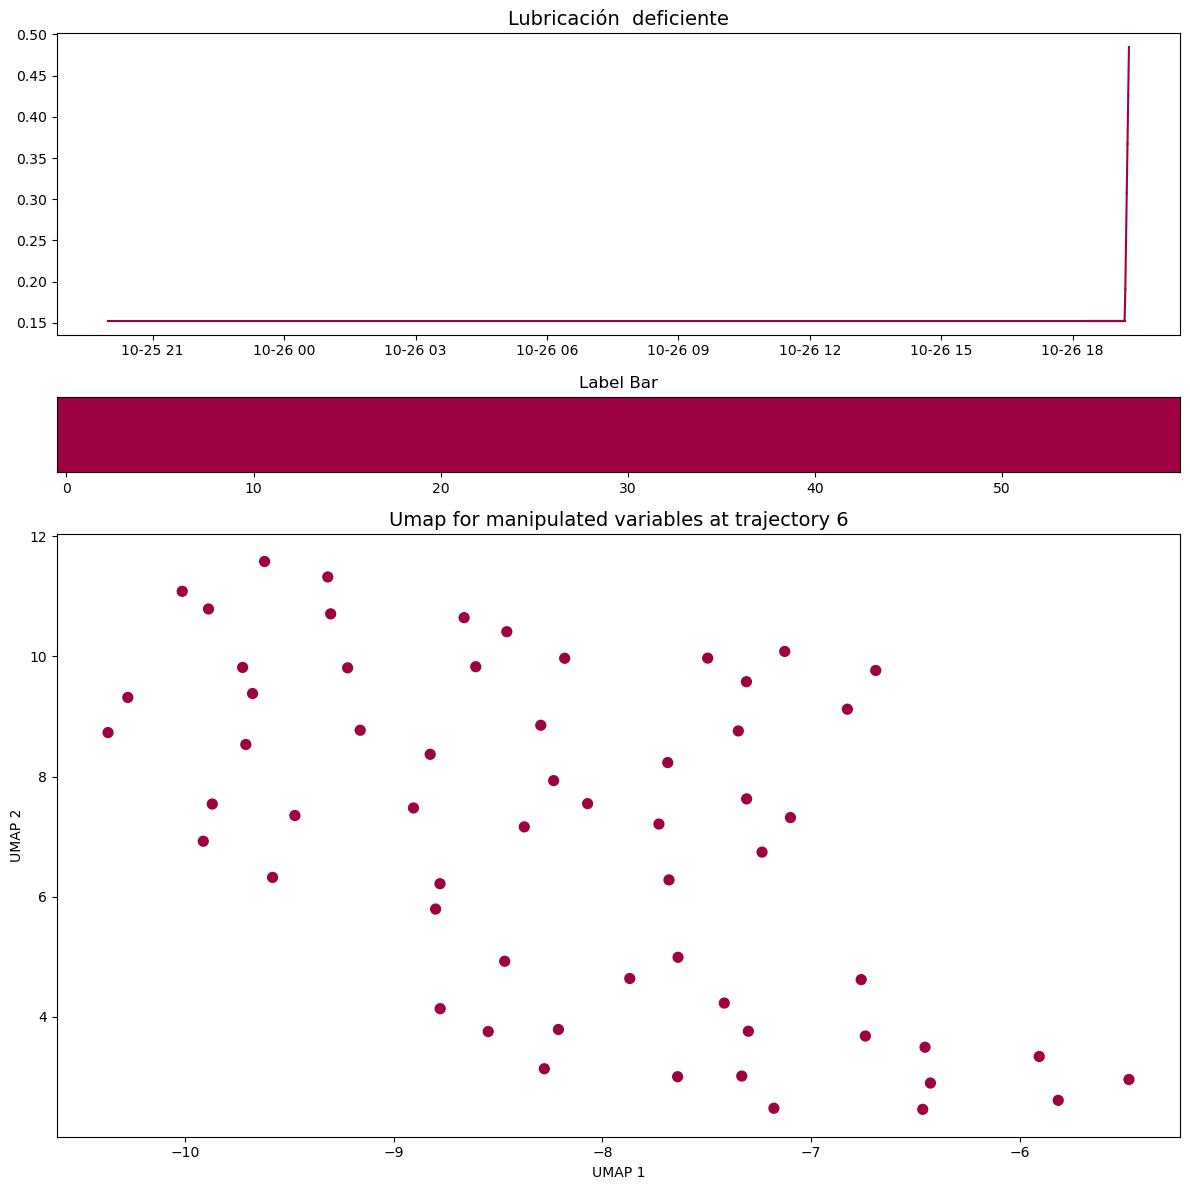

The MOF Temperatura fuera de rango


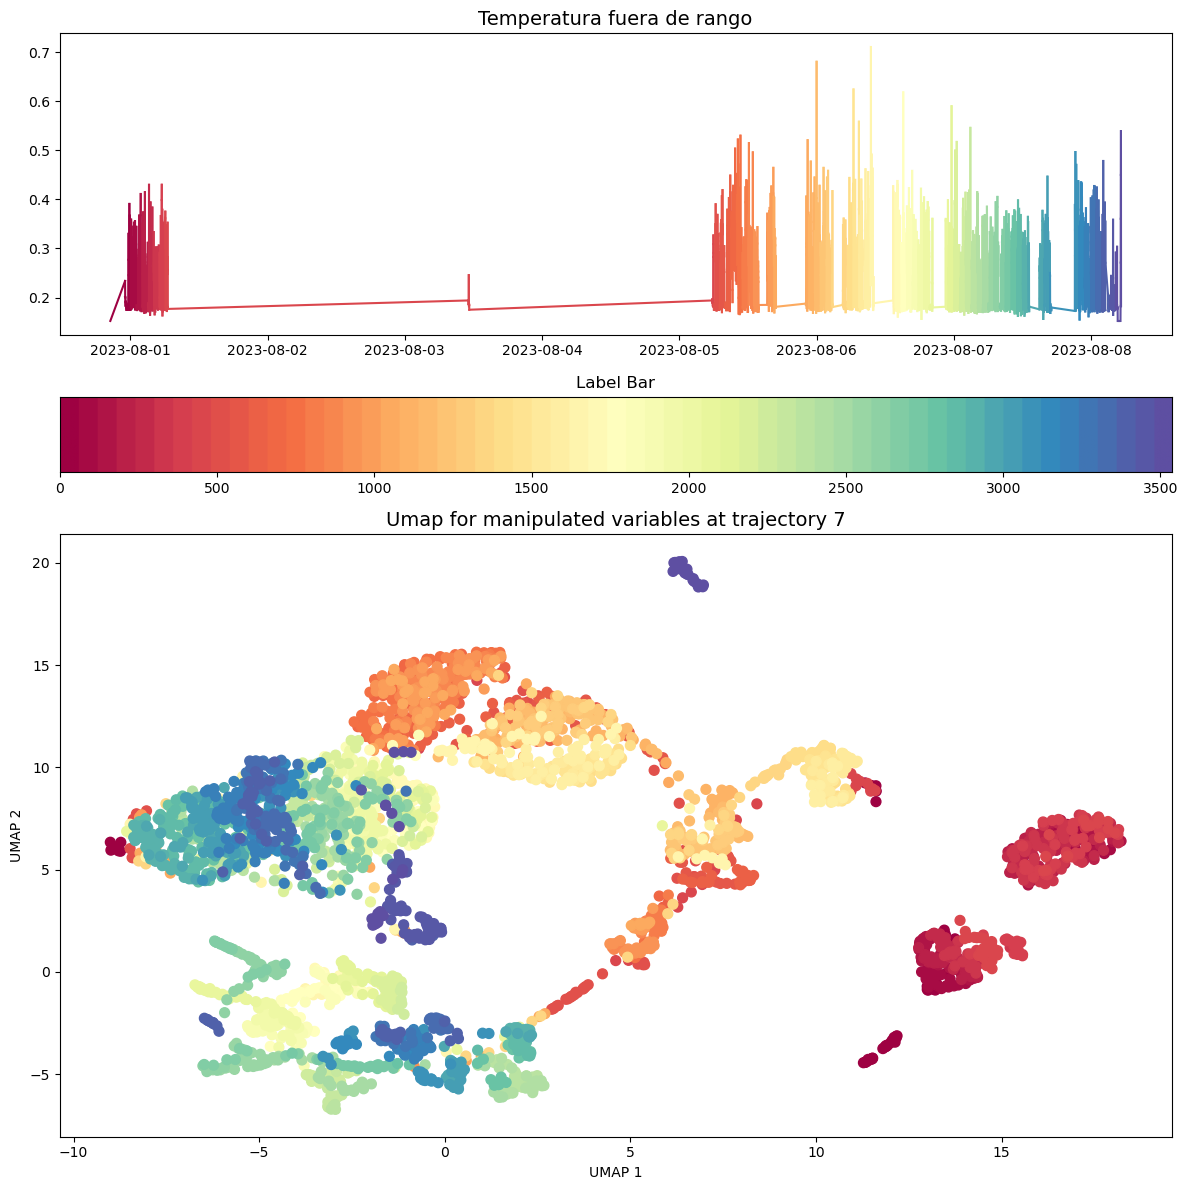

The MOF Bomba hidráulica con fuga


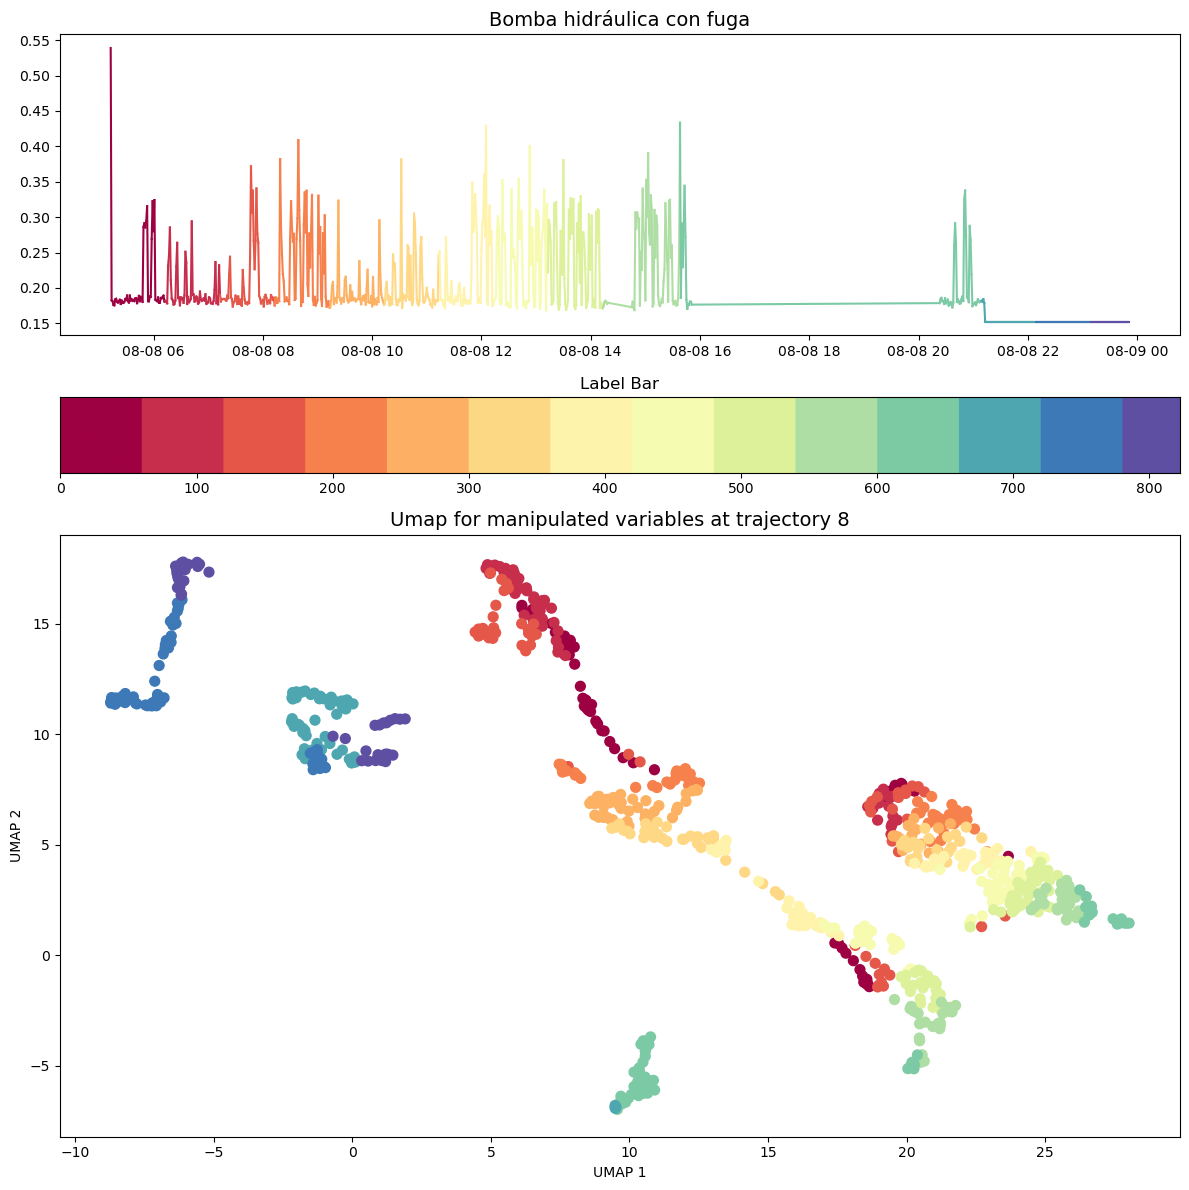

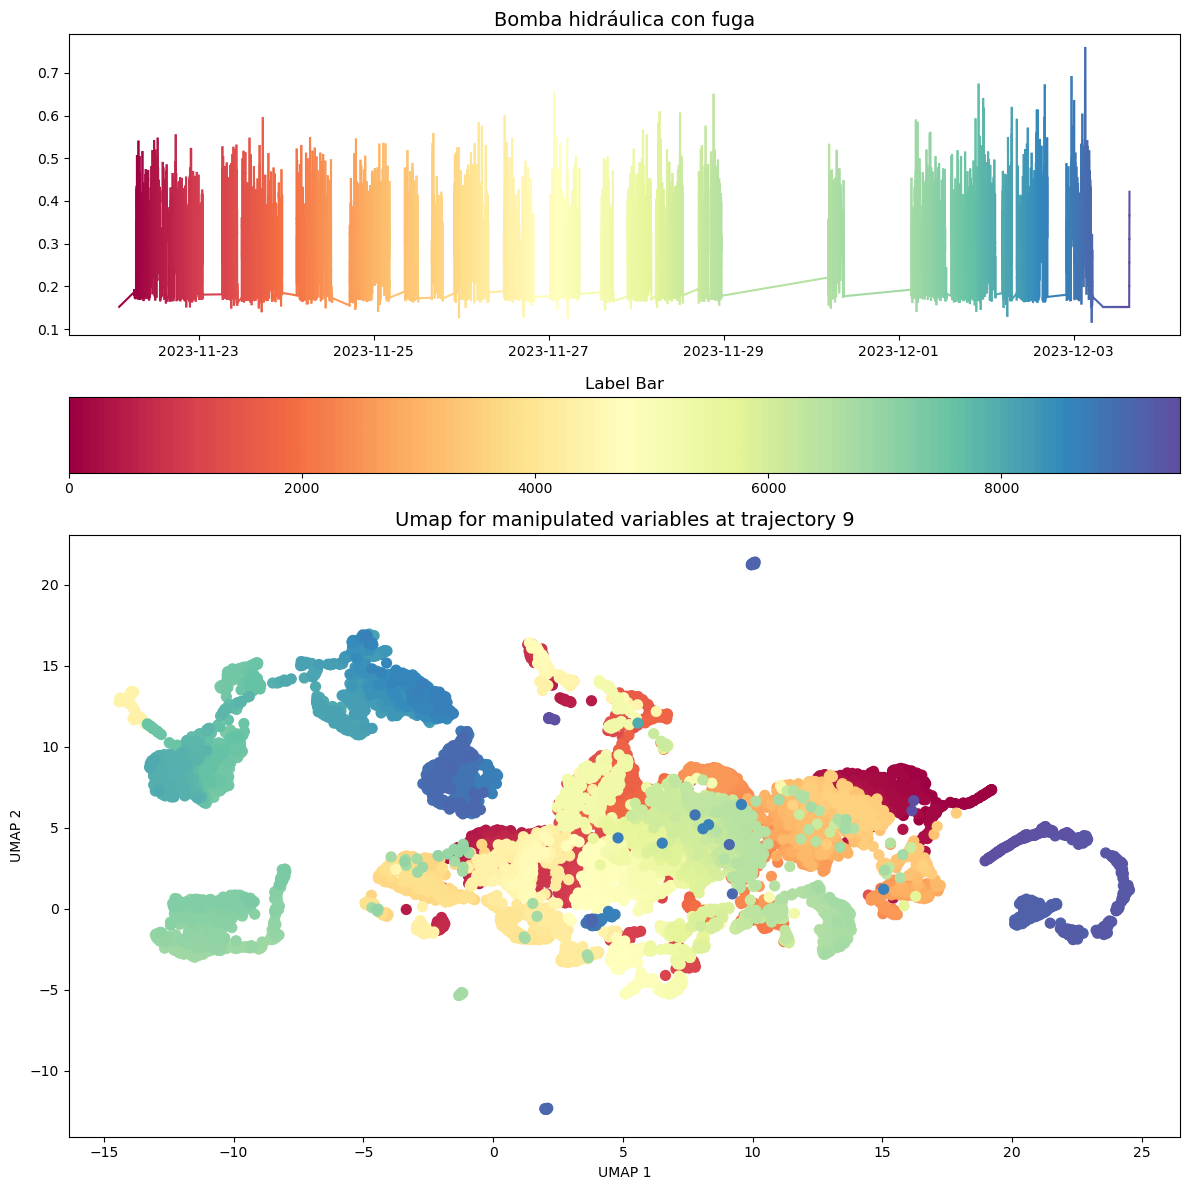

The MOF Fuga de aceite


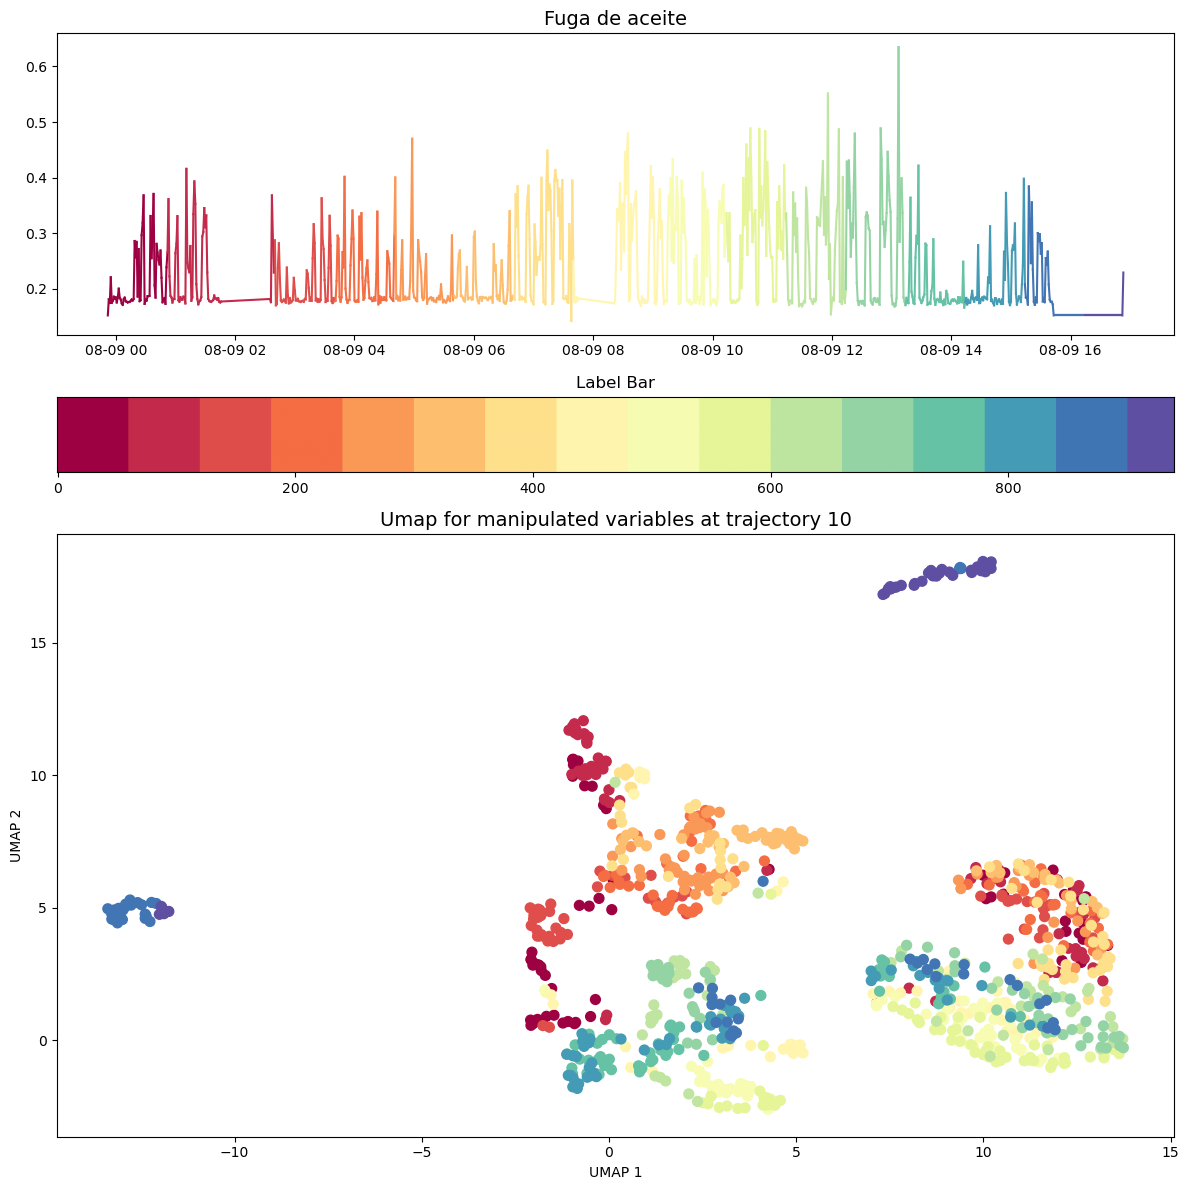

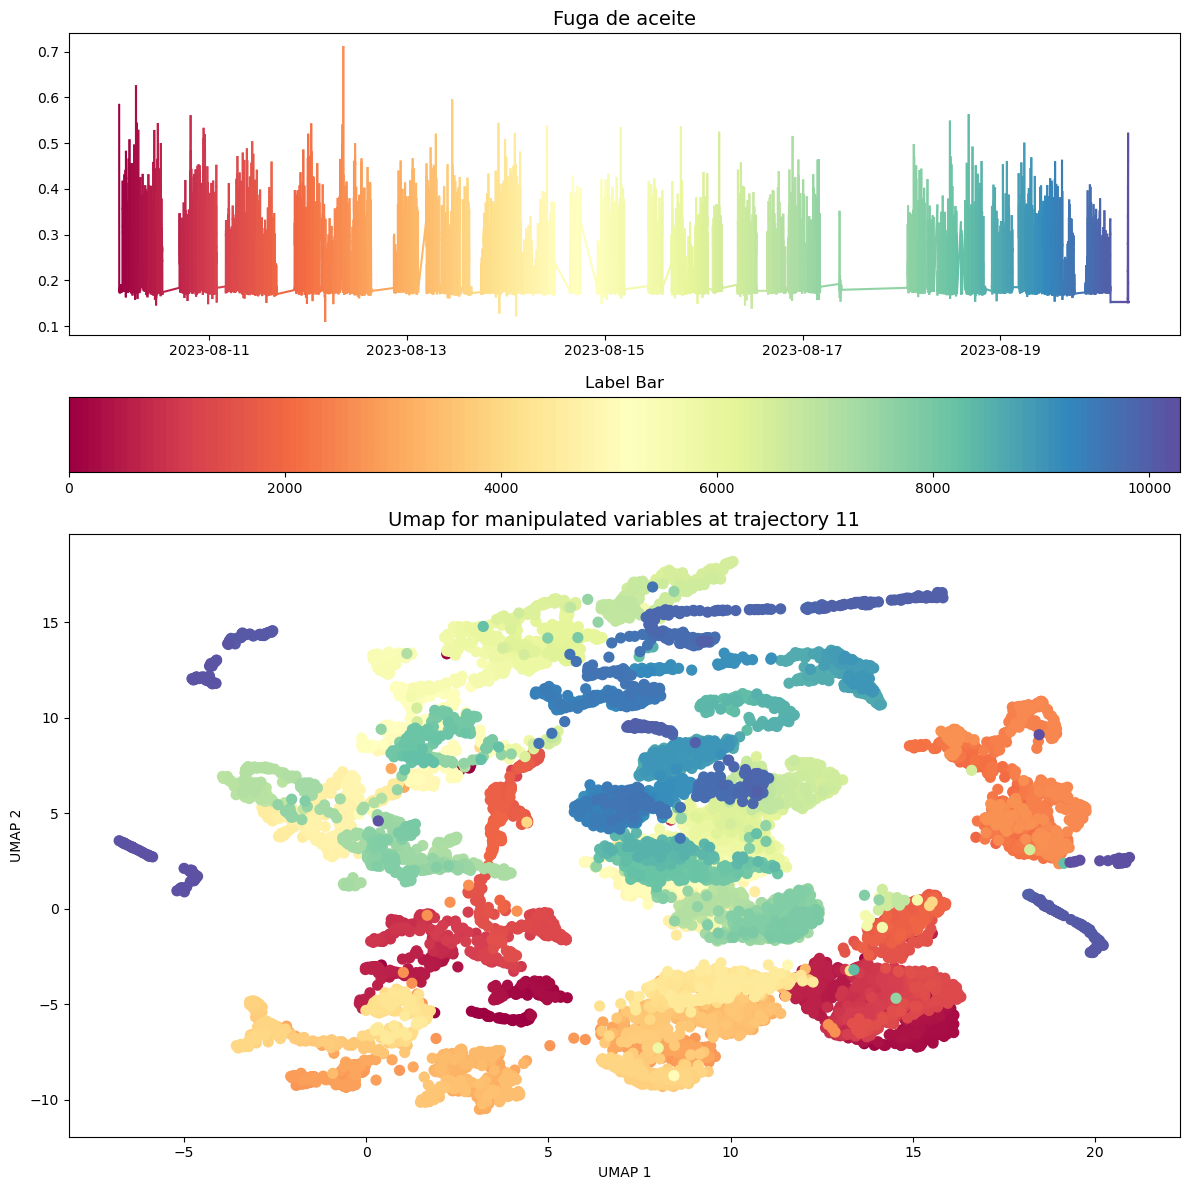

The MOF Falla sistema de hidroset-poste


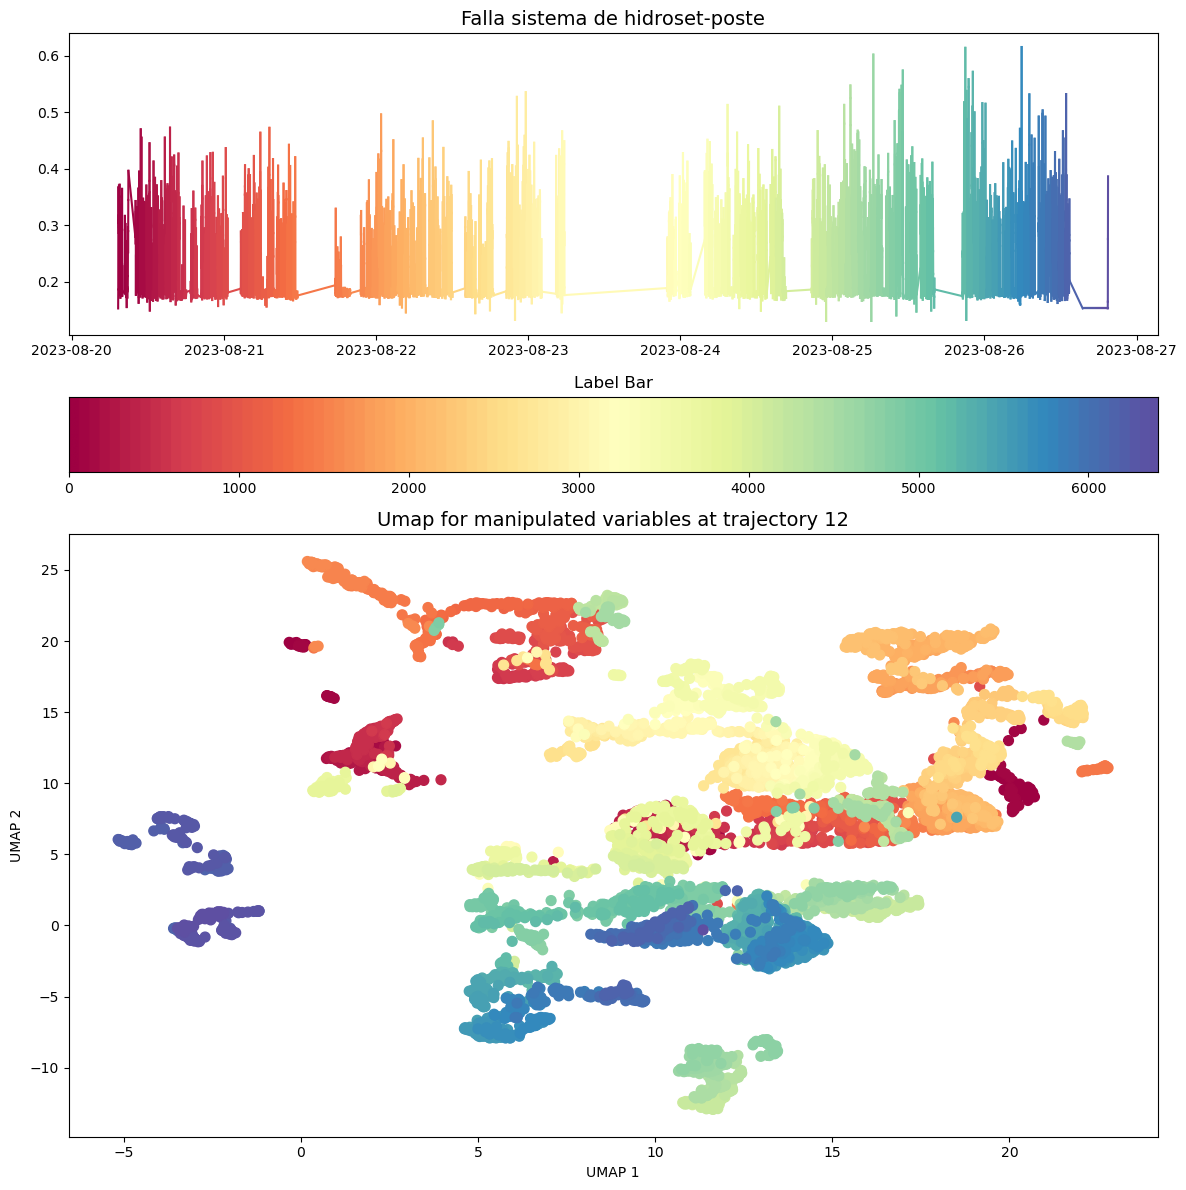

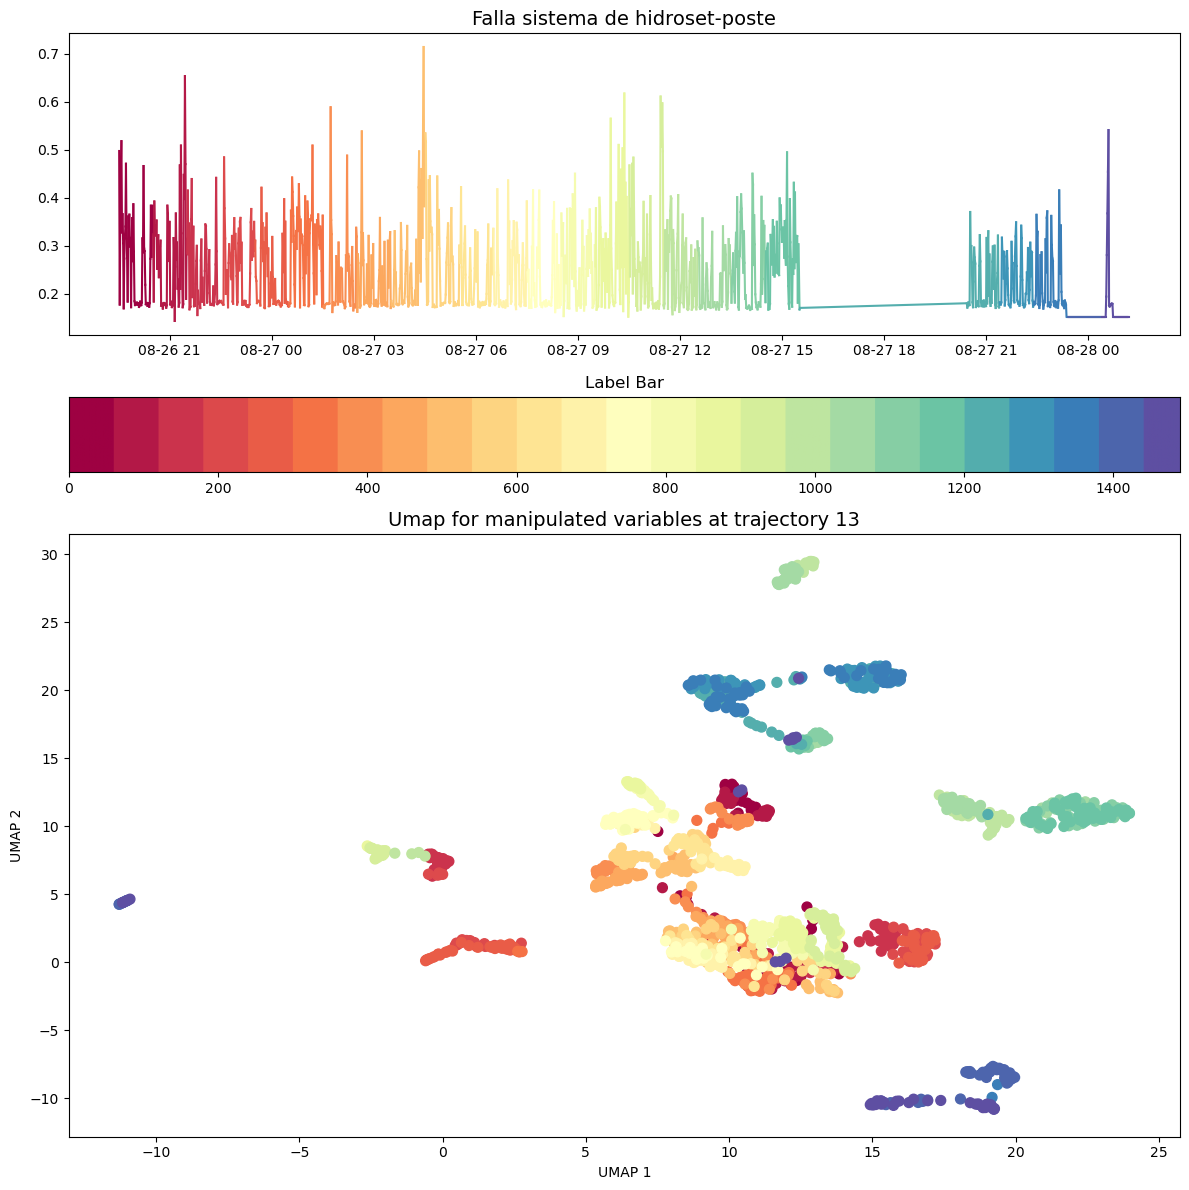

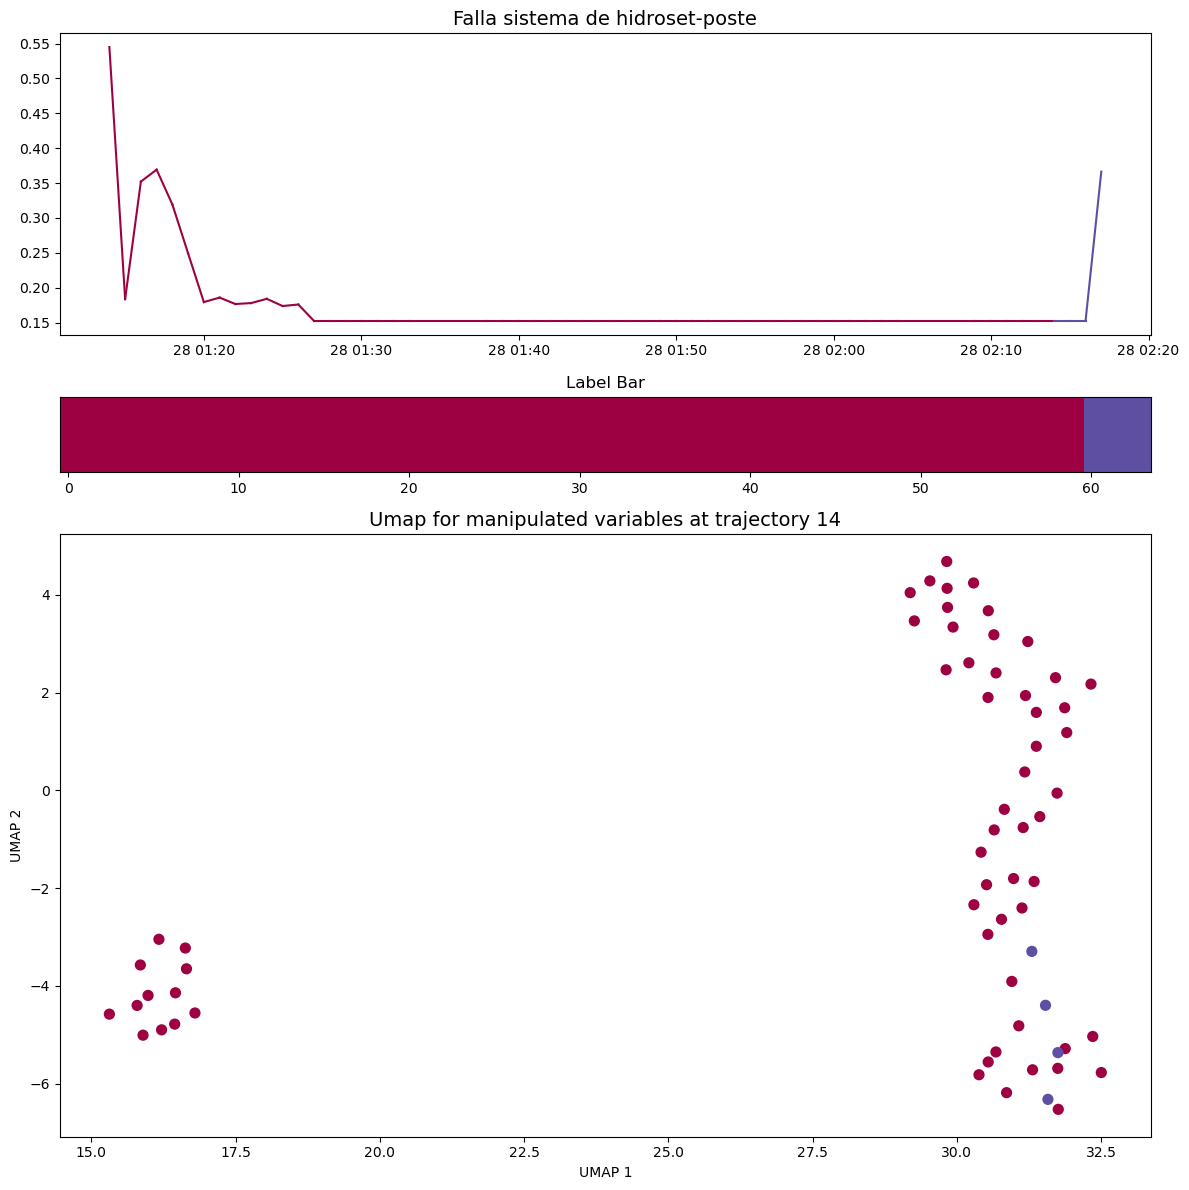

The MOF Mandibulas o revestimiento suelto


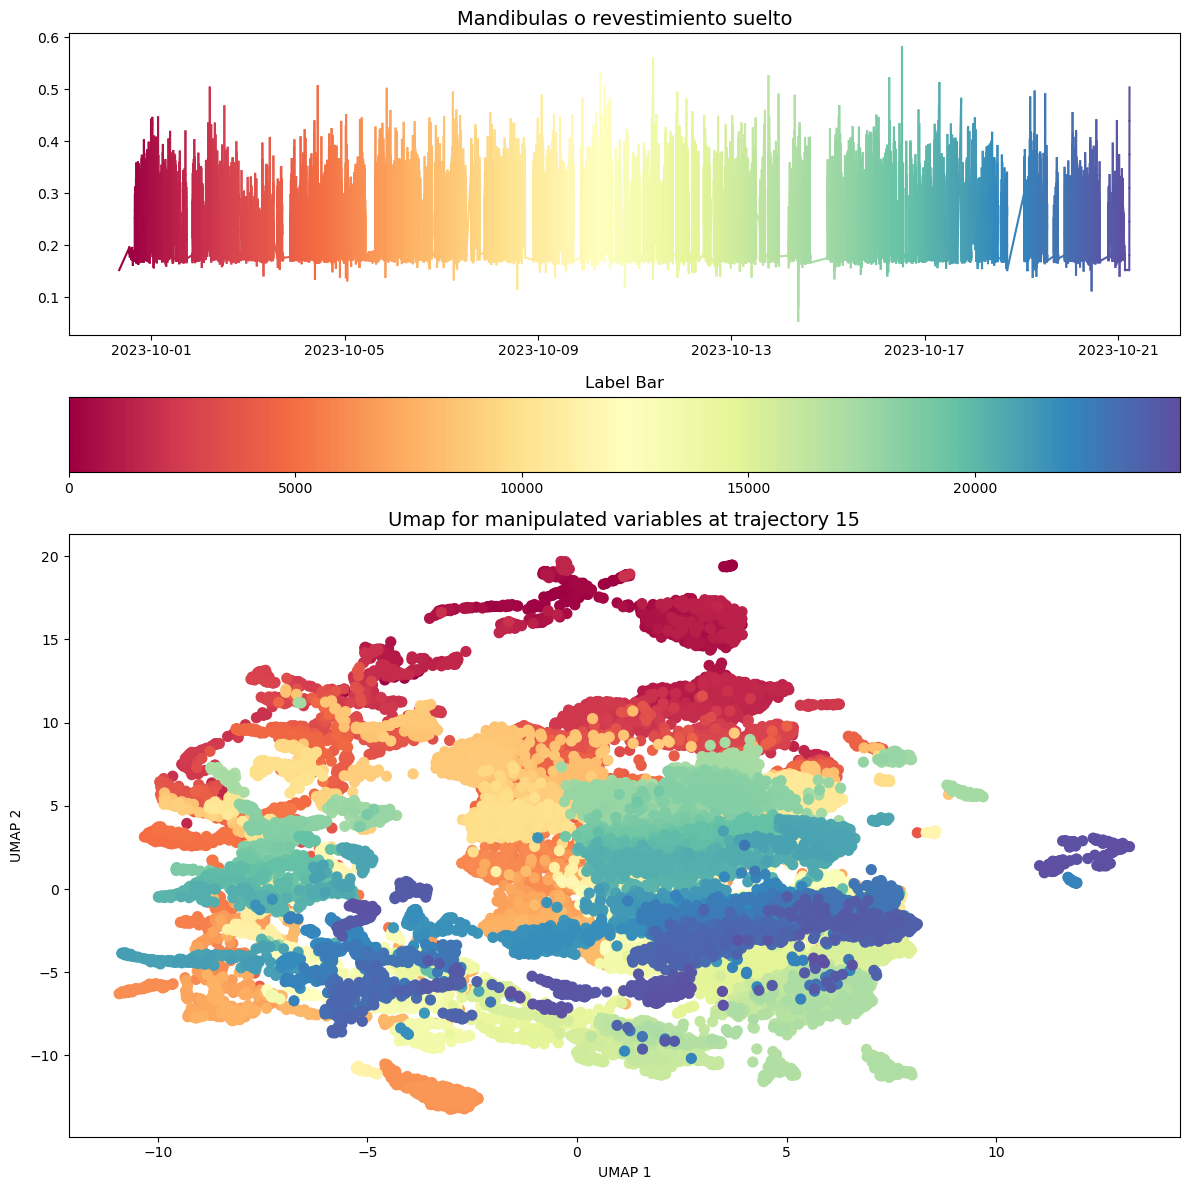

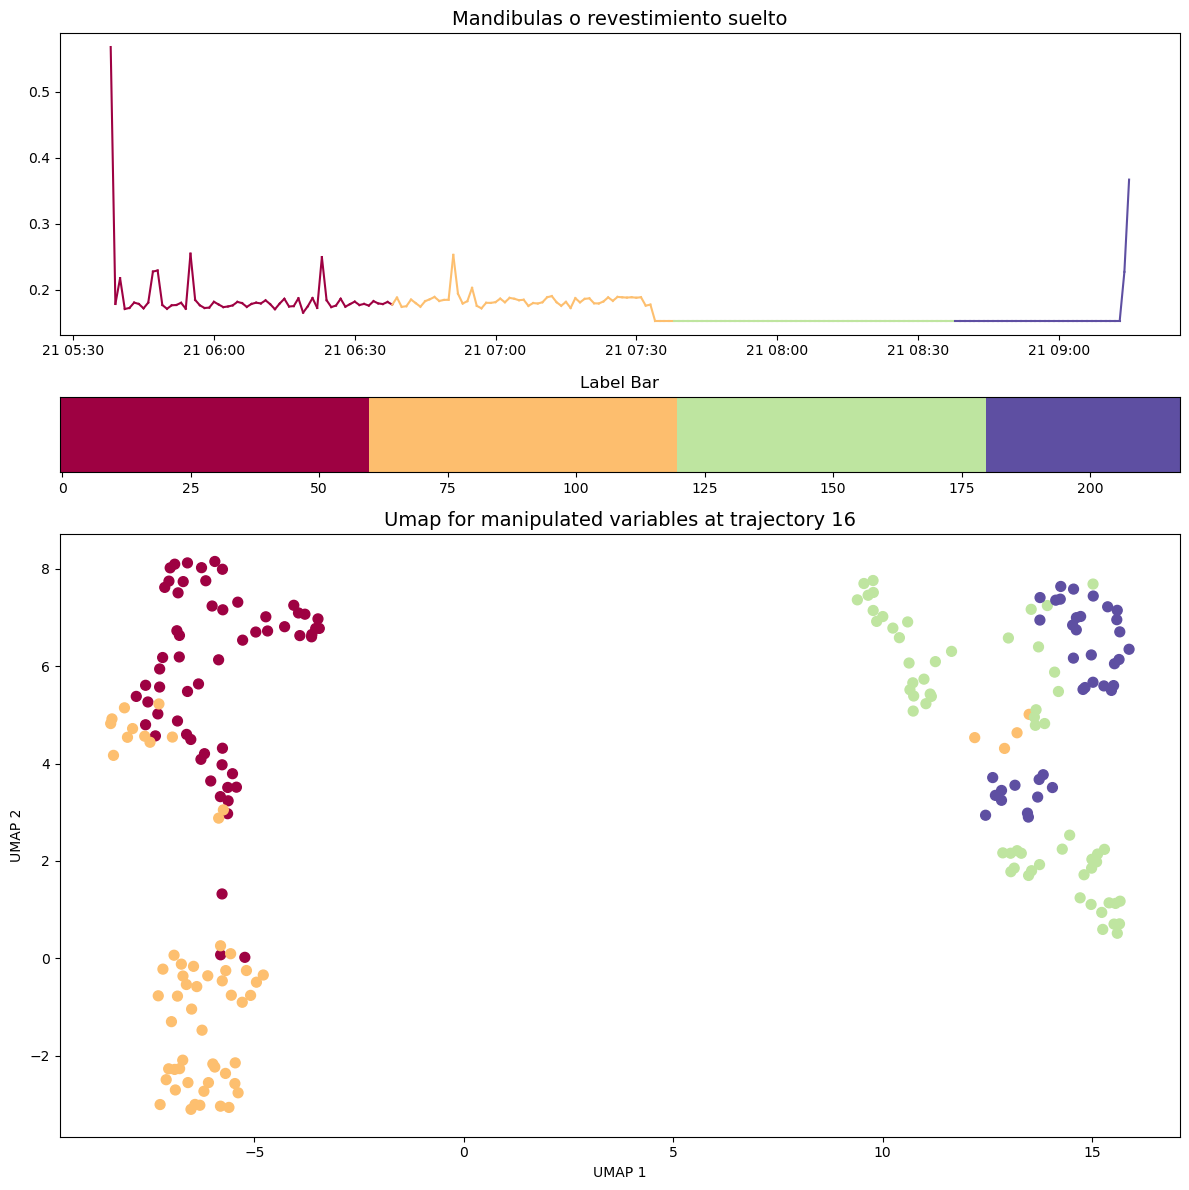

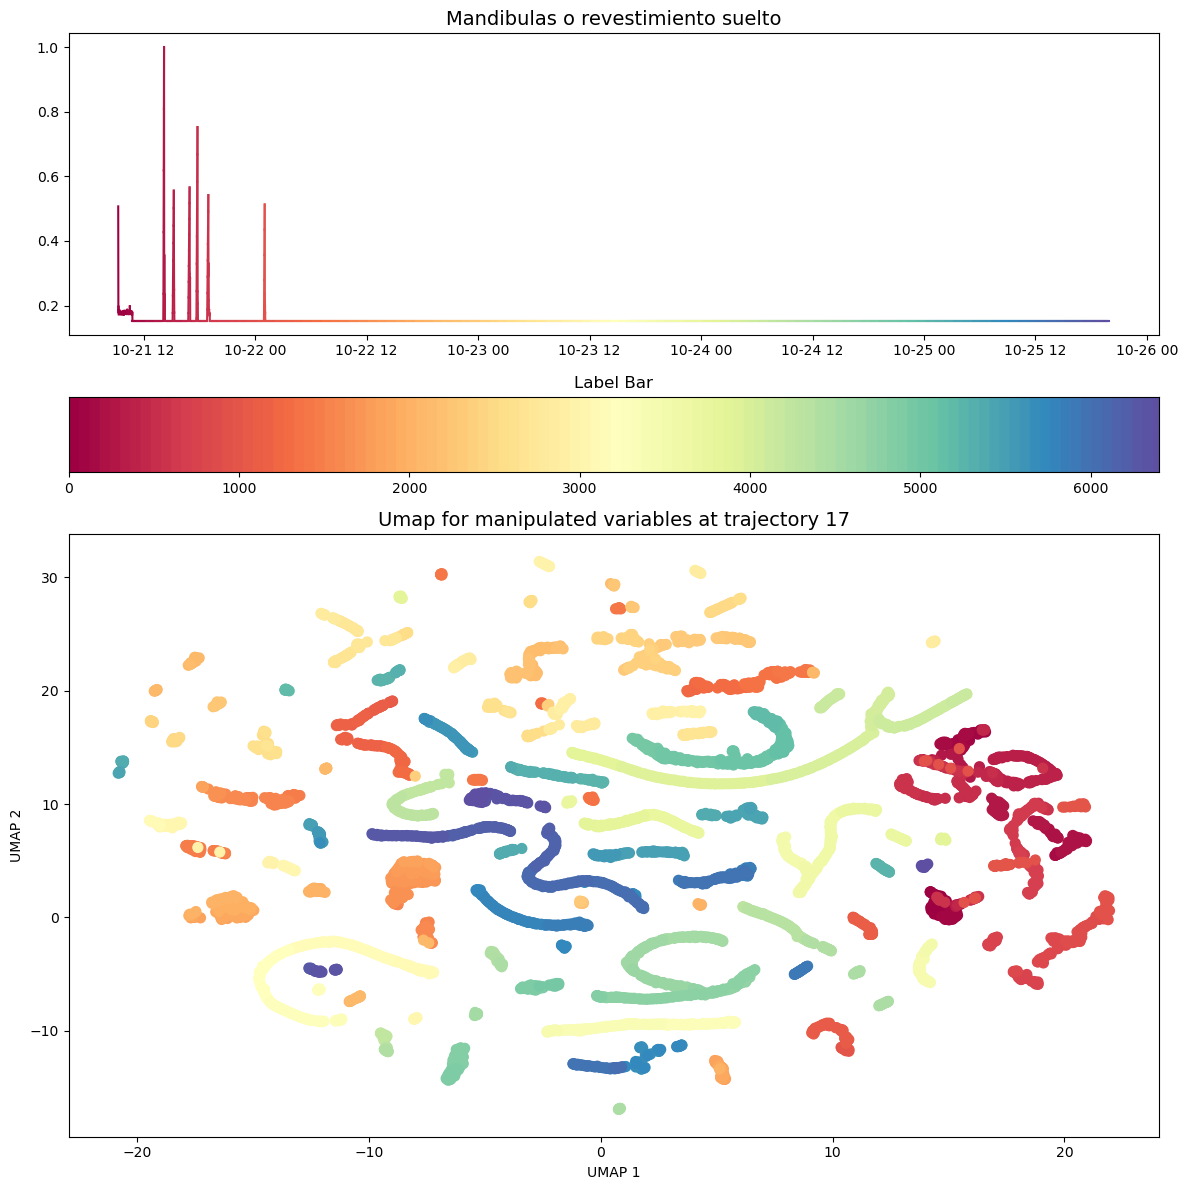

In [8]:
# sizeEachState       = 900 # 15 hours = 900min, or 60 min
sizeEachState          = 60
curTrajectory       = 0
for mof, idxTrajectList in trajectory.items():
    print(f"The MOF {mof}")
    for curTraject in idxTrajectList:

        lengthData = len(curTraject)
        # if lengthData >= 1440:
        #     sizeEachState   = 720
        # elif lengthData > 720:
        #     sizeEachState   = 180
        # else:
        #     sizeEachState   = 60
        # -----------------------------
        # Generate the label for the UMAP
        # -----------------------------
        labels              = np.repeat(np.arange(1, (curTraject.shape[0] // sizeEachState) + 1), sizeEachState)
        num_full_groups     = curTraject.shape[0] // sizeEachState
        remainder           = curTraject.shape[0] % sizeEachState
        if (remainder) > 0:
            labels = np.concatenate([labels, np.full(remainder, num_full_groups + 1)])
        
        # -----------------------------
        # Transform the UMAP
        # -----------------------------
        efficiencyTraject   = curTraject[preData.manipulatedCr1]     # Extract the manipulated trajectory
        embedding           = dimReductionModels.fit_transform(efficiencyTraject)

        # -----------------------------
        # Plot
        # -----------------------------
        norm                    = Normalize(vmin=labels.min(), vmax=labels.max())
        colors                  = plt.cm.Spectral(norm(labels))
        fig, (ax1, ax2, ax3)    = plt.subplots(3, 1, figsize=(12, 12), gridspec_kw={'height_ratios': [2, 0.5, 4]})

        testSignal = curTraject["Potencia(kW)"]
        time       = curTraject["tiempo"]
        for i in range(len(testSignal) - 1):
            ax1.plot(time.iloc[i:i+2], testSignal[i:i+2], color=colors[i])

        ax1.set_title(mof, fontsize=14)
        
        ax2.imshow([colors], aspect='auto')
        ax2.set_yticks([])
        ax2.set_title('Label Bar')
        

        # Plot the UMAP projection
        scatter = ax3.scatter(embedding[:, 0], embedding[:, 1], c=labels, cmap='Spectral', s=50)
        # plt.colorbar(scatter, ax=ax3, label='Period Label')
        curTrajectory = curTrajectory + 1
        ax3.set_title(f'Umap for manipulated variables at trajectory {curTrajectory}', fontsize=14)
        ax3.set_xlabel('UMAP 1')
        ax3.set_ylabel('UMAP 2')

        plt.tight_layout()
        plt.show()